# <span style="color: yellow; font-size: 60px;">***Final Project: Cognitive Control Test Battery***</span>

<span style="color: red; font-size: 40px;">***Statistical Inference Spring 2026***</span>

<span style="color:blue; font-size: 30px;">

 ***Mohammad Amin Rashid 810102454*** <br>


In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from sklearn.utils import resample
from statsmodels.stats.outliers_influence import variance_inflation_factor


DATASET_DIR='./Data/MiyakeRevisited_DataAggr.csv'

## <span style="color: yellow; font-size: 40px;">***Part1***</span>

In [35]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

df_raw = pd.read_csv(DATASET_DIR)
df = df_raw[df_raw['Included_FinalSample'] == 1].copy()

print(f"Total raw rows: {len(df_raw)}")
print(f"Final sample size: {len(df)}")

Total raw rows: 284
Final sample size: 247


In [ ]:
df.head()


,ParticipantNr,Antisac_Mean_RT,Antisac_Median_RT,Antisac_SD_RT,Antisac_Mean_ACC,Antisac_Median_ACC,Antisac_SD_ACC,Antisac_Mean_ERR,Antisac_Median_ERR,Antisac_SD_ERR,...,NASA_NumberLetter_Effort,NASA_NBack_Performance,NASA_NBack_Effort,NASA_Stroop_Performance,NASA_Stroop_Effort,NASA_ReactionTime_Performance,NASA_ReactionTime_Effort,Raven_RawScore,Raven_PercentileScore,Included_FinalSample
0,1,448.911566,430.61750,96.176723,0.877778,1,0.329377,0.122222,0,0.329377,...,85,10,75,5,50,5.0,30.0,51,50,1
1,2,684.649530,643.43550,154.353268,0.933333,1,0.250841,0.066667,0,0.250841,...,50,40,50,10,15,15.0,10.0,49,50,1
2,3,403.700209,384.37810,106.698545,0.988889,1,0.105409,0.011111,0,0.105409,...,80,70,35,20,25,5.0,5.0,54,75,1
3,4,598.556461,554.74045,156.678236,0.844444,1,0.364464,0.155556,0,0.364464,...,40,5,10,0,5,0.0,5.0,54,75,1
4,5,562.118117,532.19860,138.066929,0.966667,1,0.180511,0.033333,0,0.180511,...,60,20,80,5,55,15.0,15.0,46,25,1


In [42]:
list(df.columns)

['ParticipantNr',
 'Antisac_Mean_RT',
 'Antisac_Median_RT',
 'Antisac_SD_RT',
 'Antisac_Mean_ACC',
 'Antisac_Median_ACC',
 'Antisac_SD_ACC',
 'Antisac_Mean_ERR',
 'Antisac_Median_ERR',
 'Antisac_SD_ERR',
 'GlobLoc_Mean_RT_No_Switch',
 'GlobLoc_Mean_RT_Switch',
 'GlobLoc_Median_RT_No_Switch',
 'GlobLoc_Median_RT_Switch',
 'GlobLoc_SD_RT_No_Switch',
 'GlobLoc_SD_RT_Switch',
 'GlobLoc_Mean_RT_Switch_Cost',
 'GlobLoc_Median_RT_Switch_Cost',
 'GlobLoc_SD_RT_Switch_Cost',
 'GlobLoc_Mean_ACC_No_Switch',
 'GlobLoc_Mean_ACC_Switch',
 'GlobLoc_Median_ACC_No_Switch',
 'GlobLoc_Median_ACC_Switch',
 'GlobLoc_SD_ACC_No_Switch',
 'GlobLoc_SD_ACC_Switch',
 'GlobLoc_Mean_ERR_No_Switch',
 'GlobLoc_Mean_ERR_Switch',
 'GlobLoc_Median_ERR_No_Switch',
 'GlobLoc_Median_ERR_Switch',
 'GlobLoc_SD_ERR_No_Switch',
 'GlobLoc_SD_ERR_Switch',
 'GlobLoc_Mean_ACC_Switch_Cost',
 'GlobLoc_Median_ACC_Switch_Cost',
 'GlobLoc_SD_ACC_Switch_Cost',
 'GlobLoc_Mean_ERR_Switch_Cost',
 'GlobLoc_Median_ERR_Switch_Cost',
 'GlobLo

In [36]:
alpha = 0.1
primary_color = '#1b4965'
secondary_color = '#62b6cb'

sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\2489386730.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['Baseline RT', 'Antisaccade RT'])


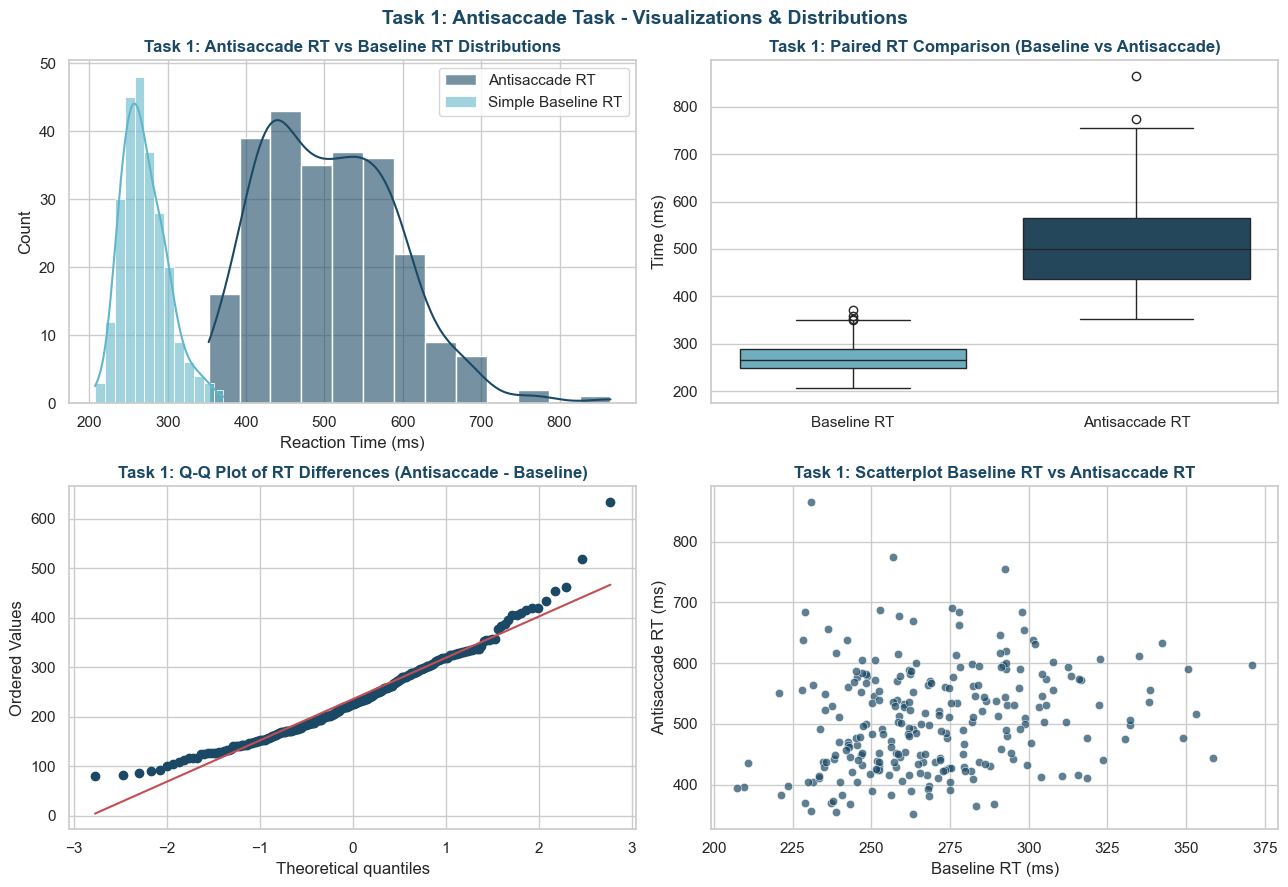

TASK 1: STATISTICAL ANALYSIS & NORMALITY TESTS
[Normality] Shapiro-Wilk (Antisaccade RT): Stat = 0.9669, p-value = 1.7085e-05 | (< 0.05: True) -> Reject Normality
[Normality] Kolmogorov-Smirnov (Antisaccade RT): Stat = 0.0845, p-value = 5.5258e-02 | (< 0.05: True) -> Reject Normality

[Comparison] Paired t-test (Antisaccade RT vs Baseline RT): t = 43.6582, p-value = 7.5259e-118 | (< 0.05: True) -> Significant Difference
[Comparison] Wilcoxon Signed-Rank: W = 0.0, p-value = 2.8676e-42 | (< 0.05: True) -> Significant Difference
[Effect Size & CI] Mean Diff = 235.43 ms | 95% CI = [224.81, 246.05] ms | Cohen's d = 2.7779


In [37]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Task 1: Antisaccade Task - Visualizations & Distributions', fontsize=14, fontweight='bold', color=primary_color)

sns.histplot(df['Antisac_Mean_RT'], kde=True, color=primary_color, label='Antisaccade RT', ax=axes[0, 0], alpha=0.6)
sns.histplot(df['RT_Mean_RT'], kde=True, color=secondary_color, label='Simple Baseline RT', ax=axes[0, 0], alpha=0.6)
axes[0, 0].set_title('Task 1: Antisaccade RT vs Baseline RT Distributions', fontweight='bold', color=primary_color)
axes[0, 0].set_xlabel('Reaction Time (ms)')
axes[0, 0].legend()

sns.boxplot(data=df[['RT_Mean_RT', 'Antisac_Mean_RT']], palette=[secondary_color, primary_color], ax=axes[0, 1])
axes[0, 1].set_xticklabels(['Baseline RT', 'Antisaccade RT'])
axes[0, 1].set_title('Task 1: Paired RT Comparison (Baseline vs Antisaccade)', fontweight='bold', color=primary_color)
axes[0, 1].set_ylabel('Time (ms)')

diff_rt = df['Antisac_Mean_RT'] - df['RT_Mean_RT']
stats.probplot(diff_rt, dist="norm", plot=axes[1, 0])
axes[1, 0].get_lines()[0].set_color(primary_color)
axes[1, 0].set_title('Task 1: Q-Q Plot of RT Differences (Antisaccade - Baseline)', fontweight='bold', color=primary_color)


sns.scatterplot(x='RT_Mean_RT', y='Antisac_Mean_RT', data=df, color=primary_color, alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title('Task 1: Scatterplot Baseline RT vs Antisaccade RT', fontweight='bold', color=primary_color)
axes[1, 1].set_xlabel('Baseline RT (ms)')
axes[1, 1].set_ylabel('Antisaccade RT (ms)')

plt.tight_layout()
plt.show()


print("="*60)
print("TASK 1: STATISTICAL ANALYSIS & NORMALITY TESTS")
print("="*60)


shapiro_rt = stats.shapiro(df['Antisac_Mean_RT'].dropna())
std_rt = (df['Antisac_Mean_RT'] - df['Antisac_Mean_RT'].mean()) / df['Antisac_Mean_RT'].std()
ks_rt = stats.kstest(std_rt.dropna(), 'norm')

print(f"[Normality] Shapiro-Wilk (Antisaccade RT): Stat = {shapiro_rt.statistic:.4f}, p-value = {shapiro_rt.pvalue:.4e} | (< 0.05: {shapiro_rt.pvalue < alpha}) -> {'Reject Normality' if shapiro_rt.pvalue < alpha else 'Fail to Reject Normality'}")
print(f"[Normality] Kolmogorov-Smirnov (Antisaccade RT): Stat = {ks_rt.statistic:.4f}, p-value = {ks_rt.pvalue:.4e} | (< 0.05: {ks_rt.pvalue < alpha}) -> {'Reject Normality' if ks_rt.pvalue < alpha else 'Fail to Reject Normality'}")


ttest_res = stats.ttest_rel(df['Antisac_Mean_RT'], df['RT_Mean_RT'])
wilcoxon_res = stats.wilcoxon(df['Antisac_Mean_RT'], df['RT_Mean_RT'])

d_val = np.mean(diff_rt) / np.std(diff_rt, ddof=1)
ci_val = stats.t.interval(0.95, df=len(diff_rt)-1, loc=np.mean(diff_rt), scale=stats.sem(diff_rt))

print(f"\n[Comparison] Paired t-test (Antisaccade RT vs Baseline RT): t = {ttest_res.statistic:.4f}, p-value = {ttest_res.pvalue:.4e} | (< 0.05: {ttest_res.pvalue < alpha}) -> Significant Difference")
print(f"[Comparison] Wilcoxon Signed-Rank: W = {wilcoxon_res.statistic:.1f}, p-value = {wilcoxon_res.pvalue:.4e} | (< 0.05: {wilcoxon_res.pvalue < alpha}) -> Significant Difference")
print(f"[Effect Size & CI] Mean Diff = {np.mean(diff_rt):.2f} ms | 95% CI = [{ci_val[0]:.2f}, {ci_val[1]:.2f}] ms | Cohen's d = {d_val:.4f}")

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\2235743883.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['Go Error (Omission)', 'No-Go Error (Commission)'])


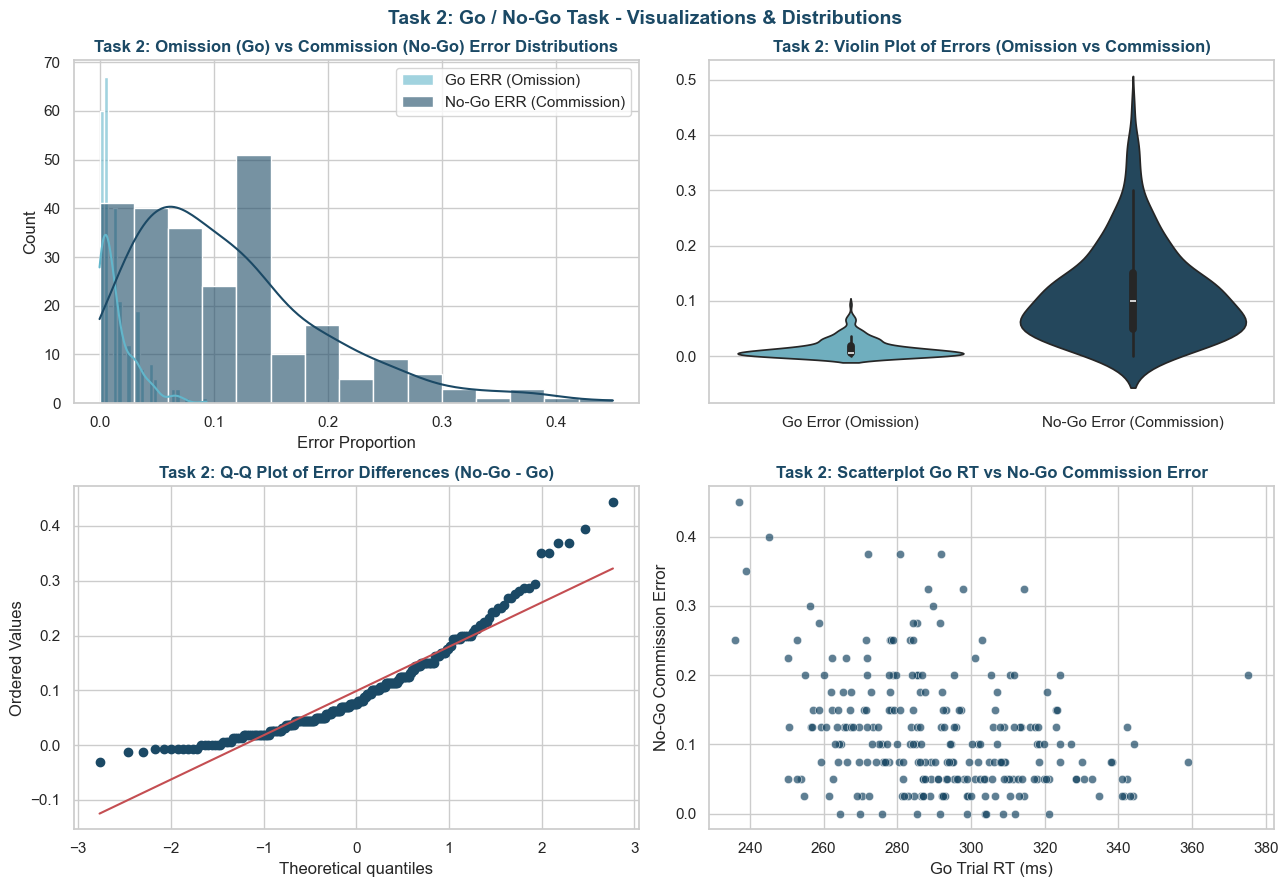

TASK 2: STATISTICAL ANALYSIS & NORMALITY TESTS
[Normality] Shapiro-Wilk (Error Diff): Stat = 0.9078, p-value = 3.3994e-11 | (< 0.05: True) -> Reject Normality
[Normality] Kolmogorov-Smirnov (Error Diff): Stat = 0.1172, p-value = 2.0532e-03 | (< 0.05: True) -> Reject Normality

[Comparison] Paired t-test (No-Go Commission vs Go Omission ERR): t = 18.4427, p-value = 2.7824e-48 | (< 0.05: True) -> Significant Difference
[Comparison] Wilcoxon Signed-Rank: W = 120.5, p-value = 1.7644e-40 | (< 0.05: True) -> Significant Difference
[Effect Size & CI] Mean Diff = 9.88% | 95% CI = [8.82%, 10.93%] | Cohen's d = 1.1735


In [31]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Task 2: Go / No-Go Task - Visualizations & Distributions', fontsize=14, fontweight='bold', color=primary_color)


sns.histplot(df['GoNoGo_Mean_ERR_Go'], kde=True, color=secondary_color, label='Go ERR (Omission)', ax=axes[0, 0], alpha=0.6)
sns.histplot(df['GoNoGo_Mean_ERR_NoGo'], kde=True, color=primary_color, label='No-Go ERR (Commission)', ax=axes[0, 0], alpha=0.6)
axes[0, 0].set_title('Task 2: Omission (Go) vs Commission (No-Go) Error Distributions', fontweight='bold', color=primary_color)
axes[0, 0].set_xlabel('Error Proportion')
axes[0, 0].legend()


sns.violinplot(data=df[['GoNoGo_Mean_ERR_Go', 'GoNoGo_Mean_ERR_NoGo']], palette=[secondary_color, primary_color], ax=axes[0, 1])
axes[0, 1].set_xticklabels(['Go Error (Omission)', 'No-Go Error (Commission)'])
axes[0, 1].set_title('Task 2: Violin Plot of Errors (Omission vs Commission)', fontweight='bold', color=primary_color)


err_diff = df['GoNoGo_Mean_ERR_NoGo'] - df['GoNoGo_Mean_ERR_Go']
stats.probplot(err_diff, dist="norm", plot=axes[1, 0])
axes[1, 0].get_lines()[0].set_color(primary_color)
axes[1, 0].set_title('Task 2: Q-Q Plot of Error Differences (No-Go - Go)', fontweight='bold', color=primary_color)


sns.scatterplot(x='GoNoGo_Mean_RT_Go', y='GoNoGo_Mean_ERR_NoGo', data=df, color=primary_color, alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title('Task 2: Scatterplot Go RT vs No-Go Commission Error', fontweight='bold', color=primary_color)
axes[1, 1].set_xlabel('Go Trial RT (ms)')
axes[1, 1].set_ylabel('No-Go Commission Error')

plt.tight_layout()
plt.show()


print("="*60)
print("TASK 2: STATISTICAL ANALYSIS & NORMALITY TESTS")
print("="*60)

shapiro_err = stats.shapiro(err_diff.dropna())
std_err_diff = (err_diff - err_diff.mean()) / err_diff.std()
ks_err = stats.kstest(std_err_diff.dropna(), 'norm')

print(f"[Normality] Shapiro-Wilk (Error Diff): Stat = {shapiro_err.statistic:.4f}, p-value = {shapiro_err.pvalue:.4e} | (< 0.05: {shapiro_err.pvalue < alpha}) -> {'Reject Normality' if shapiro_err.pvalue < alpha else 'Fail to Reject Normality'}")
print(f"[Normality] Kolmogorov-Smirnov (Error Diff): Stat = {ks_err.statistic:.4f}, p-value = {ks_err.pvalue:.4e} | (< 0.05: {ks_err.pvalue < alpha}) -> {'Reject Normality' if ks_err.pvalue < alpha else 'Fail to Reject Normality'}")

ttest_err = stats.ttest_rel(df['GoNoGo_Mean_ERR_NoGo'], df['GoNoGo_Mean_ERR_Go'])
wilcoxon_err = stats.wilcoxon(df['GoNoGo_Mean_ERR_NoGo'], df['GoNoGo_Mean_ERR_Go'])

d_err = np.mean(err_diff) / np.std(err_diff, ddof=1)
ci_err = stats.t.interval(0.95, df=len(err_diff)-1, loc=np.mean(err_diff), scale=stats.sem(err_diff))

print(f"\n[Comparison] Paired t-test (No-Go Commission vs Go Omission ERR): t = {ttest_err.statistic:.4f}, p-value = {ttest_err.pvalue:.4e} | (< 0.05: {ttest_err.pvalue < alpha}) -> Significant Difference")
print(f"[Comparison] Wilcoxon Signed-Rank: W = {wilcoxon_err.statistic:.1f}, p-value = {wilcoxon_err.pvalue:.4e} | (< 0.05: {wilcoxon_err.pvalue < alpha}) -> Significant Difference")
print(f"[Effect Size & CI] Mean Diff = {np.mean(err_diff)*100:.2f}% | 95% CI = [{ci_err[0]*100:.2f}%, {ci_err[1]*100:.2f}%] | Cohen's d = {d_err:.4f}")

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\2049155604.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['Congruent (C)', 'Incongruent (I)'])


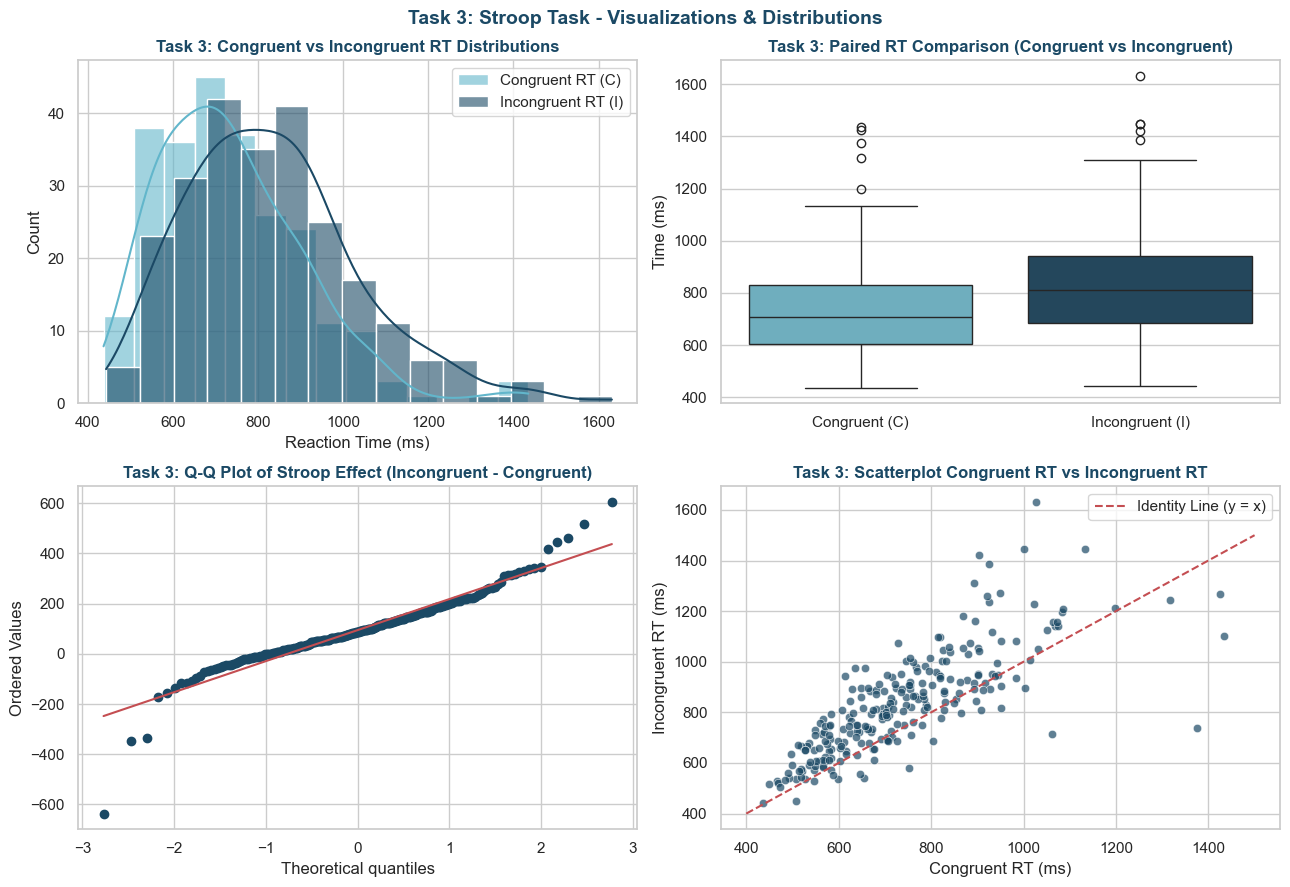

TASK 3: STATISTICAL ANALYSIS & NORMALITY TESTS
[Normality] Shapiro-Wilk (Stroop Effect): Stat = 0.9278, p-value = 1.3016e-09 | (< 0.05: True) -> Reject Normality
[Normality] Kolmogorov-Smirnov (Stroop Effect): Stat = 0.0757, p-value = 1.1240e-01 | (< 0.05: False) -> Fail to Reject Normality

[Comparison] Paired t-test (Incongruent vs Congruent RT): t = 11.5953, p-value = 4.3368e-25 | (< 0.05: True) -> Significant Difference
[Comparison] Wilcoxon Signed-Rank: W = 3163.0, p-value = 3.0741e-27 | (< 0.05: True) -> Significant Difference
[Effect Size & CI] Mean Stroop Effect = 94.44 ms | 95% CI = [78.40, 110.48] ms | Cohen's d = 0.7378


In [32]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Task 3: Stroop Task - Visualizations & Distributions', fontsize=14, fontweight='bold', color=primary_color)


sns.histplot(df['Stroop_Mean_RT_C'], kde=True, color=secondary_color, label='Congruent RT (C)', ax=axes[0, 0], alpha=0.6)
sns.histplot(df['Stroop_Mean_RT_I'], kde=True, color=primary_color, label='Incongruent RT (I)', ax=axes[0, 0], alpha=0.6)
axes[0, 0].set_title('Task 3: Congruent vs Incongruent RT Distributions', fontweight='bold', color=primary_color)
axes[0, 0].set_xlabel('Reaction Time (ms)')
axes[0, 0].legend()


sns.boxplot(data=df[['Stroop_Mean_RT_C', 'Stroop_Mean_RT_I']], palette=[secondary_color, primary_color], ax=axes[0, 1])
axes[0, 1].set_xticklabels(['Congruent (C)', 'Incongruent (I)'])
axes[0, 1].set_title('Task 3: Paired RT Comparison (Congruent vs Incongruent)', fontweight='bold', color=primary_color)
axes[0, 1].set_ylabel('Time (ms)')


stroop_effect = df['Stroop_Mean_RT_StroopEffect'].dropna()
stats.probplot(stroop_effect, dist="norm", plot=axes[1, 0])
axes[1, 0].get_lines()[0].set_color(primary_color)
axes[1, 0].set_title('Task 3: Q-Q Plot of Stroop Effect (Incongruent - Congruent)', fontweight='bold', color=primary_color)


sns.scatterplot(x='Stroop_Mean_RT_C', y='Stroop_Mean_RT_I', data=df, color=primary_color, alpha=0.7, ax=axes[1, 1])
axes[1, 1].plot([400, 1500], [400, 1500], 'r--', label='Identity Line (y = x)')
axes[1, 1].set_title('Task 3: Scatterplot Congruent RT vs Incongruent RT', fontweight='bold', color=primary_color)
axes[1, 1].set_xlabel('Congruent RT (ms)')
axes[1, 1].set_ylabel('Incongruent RT (ms)')
axes[1, 1].legend()

plt.tight_layout()
plt.show()


print("="*60)
print("TASK 3: STATISTICAL ANALYSIS & NORMALITY TESTS")
print("="*60)

shapiro_stroop = stats.shapiro(stroop_effect)
std_stroop = (stroop_effect - stroop_effect.mean()) / stroop_effect.std()
ks_stroop = stats.kstest(std_stroop, 'norm')

print(f"[Normality] Shapiro-Wilk (Stroop Effect): Stat = {shapiro_stroop.statistic:.4f}, p-value = {shapiro_stroop.pvalue:.4e} | (< 0.05: {shapiro_stroop.pvalue < alpha}) -> {'Reject Normality' if shapiro_stroop.pvalue < alpha else 'Fail to Reject Normality'}")
print(f"[Normality] Kolmogorov-Smirnov (Stroop Effect): Stat = {ks_stroop.statistic:.4f}, p-value = {ks_stroop.pvalue:.4e} | (< 0.05: {ks_stroop.pvalue < alpha}) -> {'Reject Normality' if ks_stroop.pvalue < alpha else 'Fail to Reject Normality'}")

ttest_stroop = stats.ttest_rel(df['Stroop_Mean_RT_I'], df['Stroop_Mean_RT_C'])
wilcoxon_stroop = stats.wilcoxon(df['Stroop_Mean_RT_I'], df['Stroop_Mean_RT_C'])

d_stroop = np.mean(stroop_effect) / np.std(stroop_effect, ddof=1)
ci_stroop = stats.t.interval(0.95, df=len(stroop_effect)-1, loc=np.mean(stroop_effect), scale=stats.sem(stroop_effect))

print(f"\n[Comparison] Paired t-test (Incongruent vs Congruent RT): t = {ttest_stroop.statistic:.4f}, p-value = {ttest_stroop.pvalue:.4e} | (< 0.05: {ttest_stroop.pvalue < alpha}) -> Significant Difference")
print(f"[Comparison] Wilcoxon Signed-Rank: W = {wilcoxon_stroop.statistic:.1f}, p-value = {wilcoxon_stroop.pvalue:.4e} | (< 0.05: {wilcoxon_stroop.pvalue < alpha}) -> Significant Difference")
print(f"[Effect Size & CI] Mean Stroop Effect = {np.mean(stroop_effect):.2f} ms | 95% CI = [{ci_stroop[0]:.2f}, {ci_stroop[1]:.2f}] ms | Cohen's d = {d_stroop:.4f}")

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\4127317004.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['No-Switch', 'Switch'])


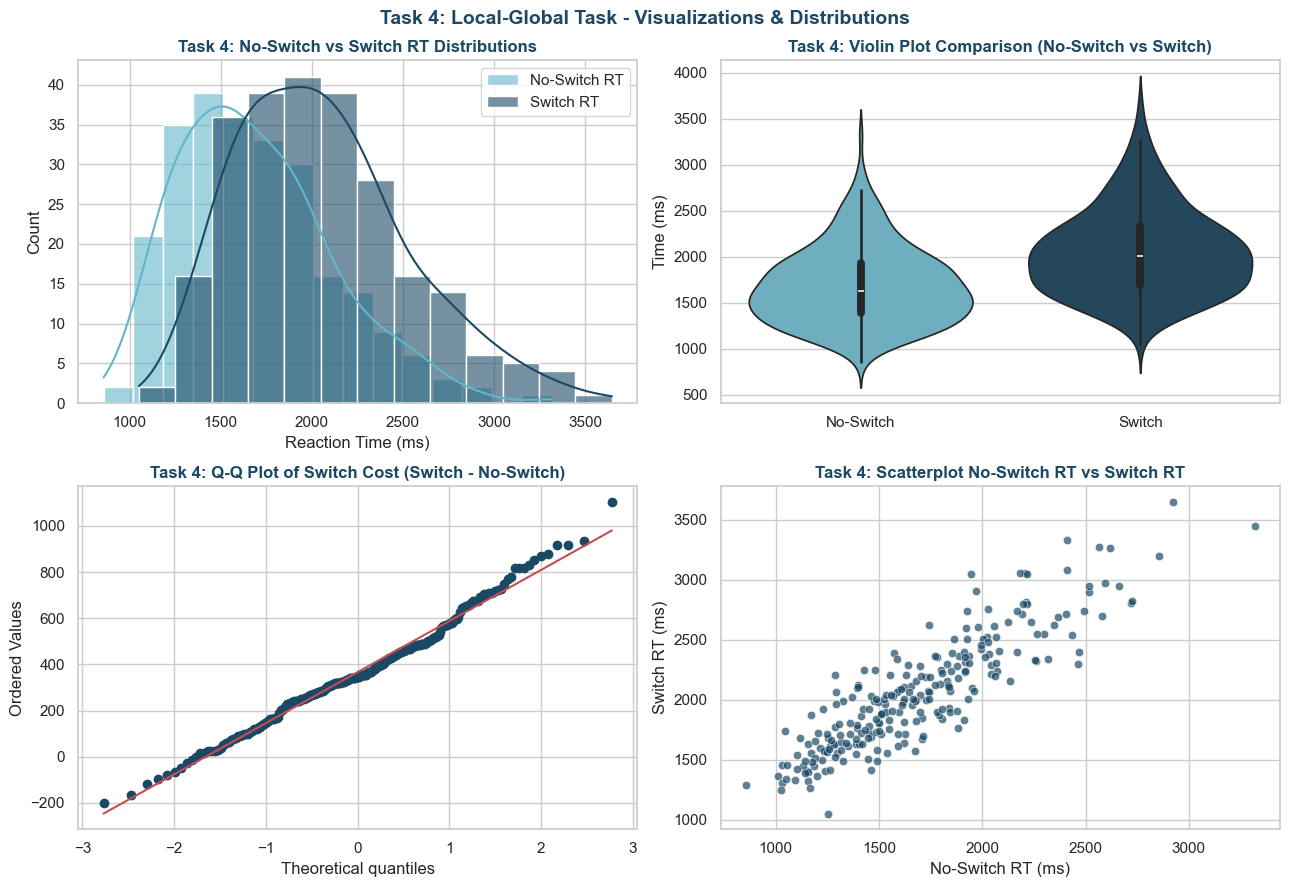

TASK 4: STATISTICAL ANALYSIS & NORMALITY TESTS
[Normality] Shapiro-Wilk (Switch Cost): Stat = 0.9887, p-value = 5.0947e-02 | (< 0.05: True) -> Reject Normality
[Normality] Kolmogorov-Smirnov (Switch Cost): Stat = 0.0610, p-value = 3.0363e-01 | (< 0.05: False) -> Fail to Reject Normality (Normal)

[Comparison] Paired t-test (Switch vs No-Switch RT): t = 26.0625, p-value = 1.0173e-72 | (< 0.05: True) -> Significant Difference
[Comparison] Wilcoxon Signed-Rank: W = 207.0, p-value = 3.5131e-41 | (< 0.05: True) -> Significant Difference
[Effect Size & CI] Mean Switch Cost = 366.66 ms | 95% CI = [338.95, 394.37] ms | Cohen's d = 1.6583


In [33]:

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Task 4: Local-Global Task - Visualizations & Distributions', fontsize=14, fontweight='bold', color=primary_color)


sns.histplot(df['GlobLoc_Mean_RT_No_Switch'], kde=True, color=secondary_color, label='No-Switch RT', ax=axes[0, 0], alpha=0.6)
sns.histplot(df['GlobLoc_Mean_RT_Switch'], kde=True, color=primary_color, label='Switch RT', ax=axes[0, 0], alpha=0.6)
axes[0, 0].set_title('Task 4: No-Switch vs Switch RT Distributions', fontweight='bold', color=primary_color)
axes[0, 0].set_xlabel('Reaction Time (ms)')
axes[0, 0].legend()


sns.violinplot(data=df[['GlobLoc_Mean_RT_No_Switch', 'GlobLoc_Mean_RT_Switch']], palette=[secondary_color, primary_color], ax=axes[0, 1])
axes[0, 1].set_xticklabels(['No-Switch', 'Switch'])
axes[0, 1].set_title('Task 4: Violin Plot Comparison (No-Switch vs Switch)', fontweight='bold', color=primary_color)
axes[0, 1].set_ylabel('Time (ms)')


lg_cost = df['GlobLoc_Mean_RT_Switch_Cost'].dropna()
stats.probplot(lg_cost, dist="norm", plot=axes[1, 0])
axes[1, 0].get_lines()[0].set_color(primary_color)
axes[1, 0].set_title('Task 4: Q-Q Plot of Switch Cost (Switch - No-Switch)', fontweight='bold', color=primary_color)


sns.scatterplot(x='GlobLoc_Mean_RT_No_Switch', y='GlobLoc_Mean_RT_Switch', data=df, color=primary_color, alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title('Task 4: Scatterplot No-Switch RT vs Switch RT', fontweight='bold', color=primary_color)
axes[1, 1].set_xlabel('No-Switch RT (ms)')
axes[1, 1].set_ylabel('Switch RT (ms)')

plt.tight_layout()
plt.show()


print("="*60)
print("TASK 4: STATISTICAL ANALYSIS & NORMALITY TESTS")
print("="*60)

shapiro_lg = stats.shapiro(lg_cost)
std_lg = (lg_cost - lg_cost.mean()) / lg_cost.std()
ks_lg = stats.kstest(std_lg, 'norm')

print(f"[Normality] Shapiro-Wilk (Switch Cost): Stat = {shapiro_lg.statistic:.4f}, p-value = {shapiro_lg.pvalue:.4e} | (< 0.05: {shapiro_lg.pvalue < alpha}) -> {'Reject Normality' if shapiro_lg.pvalue < alpha else 'Fail to Reject Normality (Normal)'}")
print(f"[Normality] Kolmogorov-Smirnov (Switch Cost): Stat = {ks_lg.statistic:.4f}, p-value = {ks_lg.pvalue:.4e} | (< 0.05: {ks_lg.pvalue < alpha}) -> {'Reject Normality' if ks_lg.pvalue < alpha else 'Fail to Reject Normality (Normal)'}")

ttest_lg = stats.ttest_rel(df['GlobLoc_Mean_RT_Switch'], df['GlobLoc_Mean_RT_No_Switch'])
wilcoxon_lg = stats.wilcoxon(df['GlobLoc_Mean_RT_Switch'], df['GlobLoc_Mean_RT_No_Switch'])

d_lg = np.mean(lg_cost) / np.std(lg_cost, ddof=1)
ci_lg = stats.t.interval(0.95, df=len(lg_cost)-1, loc=np.mean(lg_cost), scale=stats.sem(lg_cost))

print(f"\n[Comparison] Paired t-test (Switch vs No-Switch RT): t = {ttest_lg.statistic:.4f}, p-value = {ttest_lg.pvalue:.4e} | (< 0.05: {ttest_lg.pvalue < alpha}) -> Significant Difference")
print(f"[Comparison] Wilcoxon Signed-Rank: W = {wilcoxon_lg.statistic:.1f}, p-value = {wilcoxon_lg.pvalue:.4e} | (< 0.05: {wilcoxon_lg.pvalue < alpha}) -> Significant Difference")
print(f"[Effect Size & CI] Mean Switch Cost = {np.mean(lg_cost):.2f} ms | 95% CI = [{ci_lg[0]:.2f}, {ci_lg[1]:.2f}] ms | Cohen's d = {d_lg:.4f}")

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\220158754.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['Average Base Blocks', 'Switch Block'])


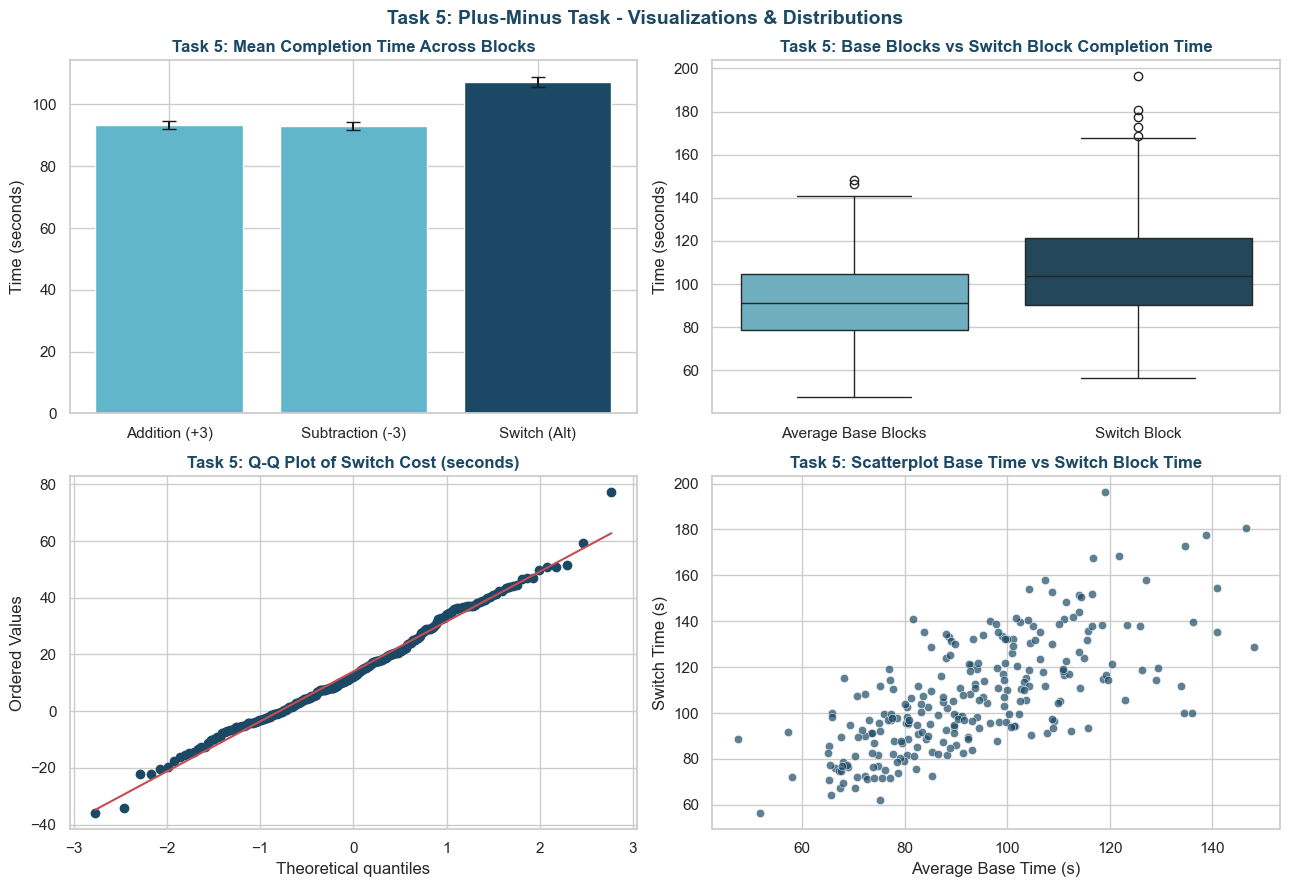

TASK 5: STATISTICAL ANALYSIS & NORMALITY TESTS
[Normality] Shapiro-Wilk (Switch Cost): Stat = 0.9919, p-value = 1.9065e-01 | (< 0.05: False) -> Fail to Reject Normality (Normal)
[Normality] Kolmogorov-Smirnov (Switch Cost): Stat = 0.0463, p-value = 6.4667e-01 | (< 0.05: False) -> Fail to Reject Normality (Normal)

[Comparison] Paired t-test (Switch Block vs Base Time): t = 12.5647, p-value = 2.6562e-28 | (< 0.05: True) -> Significant Difference
[Comparison] Wilcoxon Signed-Rank: W = 3781.0, p-value = 1.0609e-24 | (< 0.05: True) -> Significant Difference
[Effect Size & CI] Mean Switch Cost = 14.03 s | 95% CI = [11.83, 16.23] s | Cohen's d = 0.7995


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Task 5: Plus-Minus Task - Visualizations & Distributions', fontsize=14, fontweight='bold', color=primary_color)


pm_means = [df['PlusMinus_Time_Add'].mean(), df['PlusMinus_Time_Subtr'].mean(), df['PlusMinus_Time_Switch'].mean()]
pm_sems = [stats.sem(df['PlusMinus_Time_Add'].dropna()), stats.sem(df['PlusMinus_Time_Subtr'].dropna()), stats.sem(df['PlusMinus_Time_Switch'].dropna())]
axes[0, 0].bar(['Addition (+3)', 'Subtraction (-3)', 'Switch (Alt)'], pm_means, yerr=pm_sems, color=[secondary_color, secondary_color, primary_color], capsize=5)
axes[0, 0].set_title('Task 5: Mean Completion Time Across Blocks', fontweight='bold', color=primary_color)
axes[0, 0].set_ylabel('Time (seconds)')


sns.boxplot(data=df[['PlusMinus_Time_Average_Add_Subtr', 'PlusMinus_Time_Switch']], palette=[secondary_color, primary_color], ax=axes[0, 1])
axes[0, 1].set_xticklabels(['Average Base Blocks', 'Switch Block'])
axes[0, 1].set_title('Task 5: Base Blocks vs Switch Block Completion Time', fontweight='bold', color=primary_color)
axes[0, 1].set_ylabel('Time (seconds)')


pm_cost = df['PlusMinus_Time_Switch_Cost'].dropna()
stats.probplot(pm_cost, dist="norm", plot=axes[1, 0])
axes[1, 0].get_lines()[0].set_color(primary_color)
axes[1, 0].set_title('Task 5: Q-Q Plot of Switch Cost (seconds)', fontweight='bold', color=primary_color)


sns.scatterplot(x='PlusMinus_Time_Average_Add_Subtr', y='PlusMinus_Time_Switch', data=df, color=primary_color, alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title('Task 5: Scatterplot Base Time vs Switch Block Time', fontweight='bold', color=primary_color)
axes[1, 1].set_xlabel('Average Base Time (s)')
axes[1, 1].set_ylabel('Switch Time (s)')

plt.tight_layout()
plt.show()


print("="*60)
print("TASK 5: STATISTICAL ANALYSIS & NORMALITY TESTS")
print("="*60)

shapiro_pm = stats.shapiro(pm_cost)
std_pm = (pm_cost - pm_cost.mean()) / pm_cost.std()
ks_pm = stats.kstest(std_pm, 'norm')

print(f"[Normality] Shapiro-Wilk (Switch Cost): Stat = {shapiro_pm.statistic:.4f}, p-value = {shapiro_pm.pvalue:.4e} | (< 0.05: {shapiro_pm.pvalue < alpha}) -> {'Reject Normality' if shapiro_pm.pvalue < alpha else 'Fail to Reject Normality (Normal)'}")
print(f"[Normality] Kolmogorov-Smirnov (Switch Cost): Stat = {ks_pm.statistic:.4f}, p-value = {ks_pm.pvalue:.4e} | (< 0.05: {ks_pm.pvalue < alpha}) -> {'Reject Normality' if ks_pm.pvalue < alpha else 'Fail to Reject Normality (Normal)'}")

pm_avg_base = df['PlusMinus_Time_Average_Add_Subtr'].dropna()
ttest_pm = stats.ttest_rel(df['PlusMinus_Time_Switch'], pm_avg_base)
wilcoxon_pm = stats.wilcoxon(df['PlusMinus_Time_Switch'], pm_avg_base)

d_pm = np.mean(pm_cost) / np.std(pm_cost, ddof=1)
ci_pm = stats.t.interval(0.95, df=len(pm_cost)-1, loc=np.mean(pm_cost), scale=stats.sem(pm_cost))

print(f"\n[Comparison] Paired t-test (Switch Block vs Base Time): t = {ttest_pm.statistic:.4f}, p-value = {ttest_pm.pvalue:.4e} | (< 0.05: {ttest_pm.pvalue < alpha}) -> Significant Difference")
print(f"[Comparison] Wilcoxon Signed-Rank: W = {wilcoxon_pm.statistic:.1f}, p-value = {wilcoxon_pm.pvalue:.4e} | (< 0.05: {wilcoxon_pm.pvalue < alpha}) -> Significant Difference")
print(f"[Effect Size & CI] Mean Switch Cost = {np.mean(pm_cost):.2f} s | 95% CI = [{ci_pm[0]:.2f}, {ci_pm[1]:.2f}] s | Cohen's d = {d_pm:.4f}")

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\3485330819.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(['Letter Block', 'Number Block', 'Mixed Block'])
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\3485330819.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['Local No-Switch', 'Local Switch'])


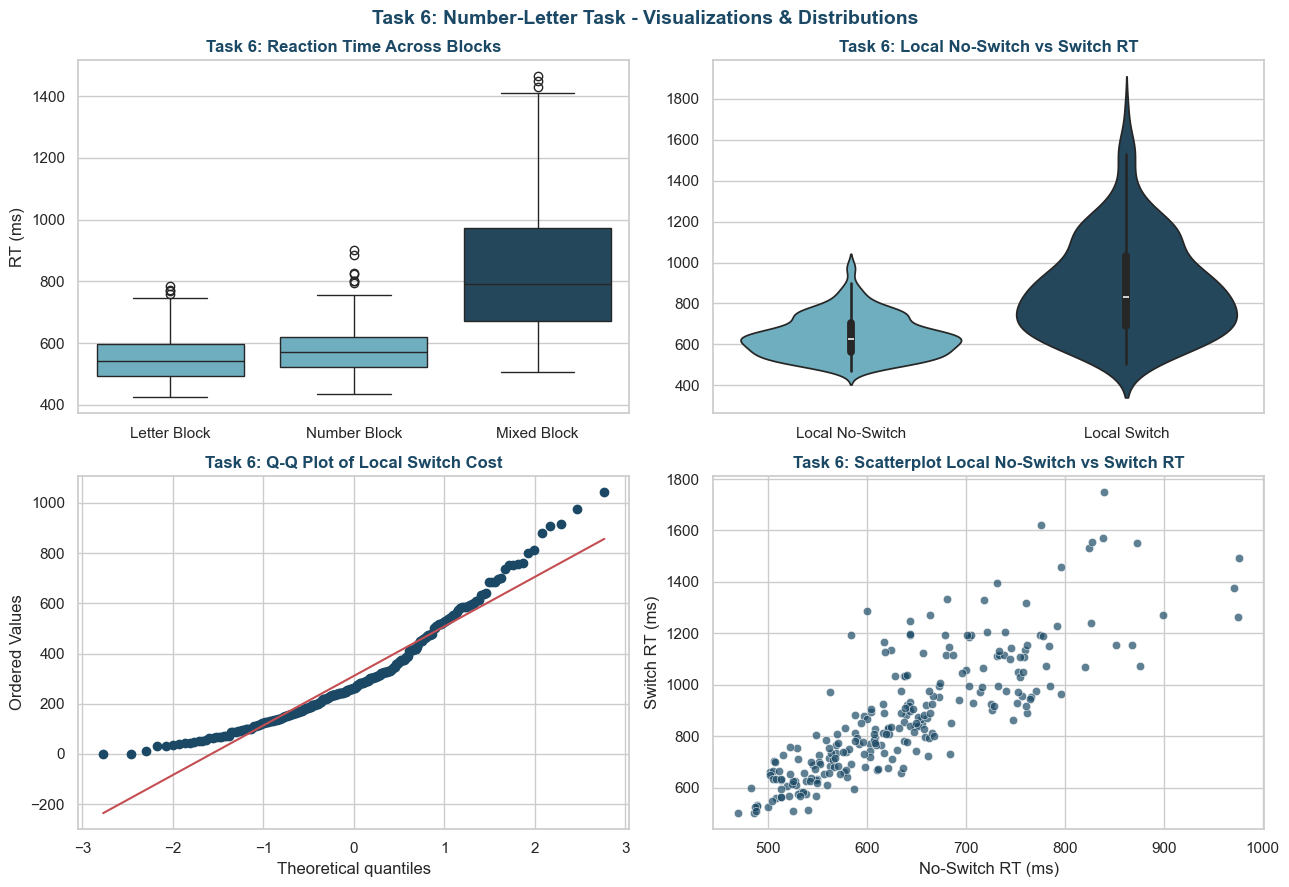

TASK 6: STATISTICAL ANALYSIS & NORMALITY TESTS
[Normality] Shapiro-Wilk (Local Cost): Stat = 0.9286, p-value = 1.5210e-09 | (< 0.05: True) -> Reject Normality
[Normality] Kolmogorov-Smirnov (Local Cost): Stat = 0.1157, p-value = 2.4423e-03 | (< 0.05: True) -> Reject Normality

[Comparison] Paired t-test (Local Switch vs No-Switch RT): t = 22.2647, p-value = 6.8907e-61 | (< 0.05: True) -> Significant Difference
[Comparison] Wilcoxon Signed-Rank: W = 11.0, p-value = 3.2788e-42 | (< 0.05: True) -> Significant Difference
[Effect Size & CI] Mean Local Cost = 310.75 ms | 95% CI = [285.30, 336.19] ms | Cohen's d = 1.5306


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Task 6: Number-Letter Task - Visualizations & Distributions', fontsize=14, fontweight='bold', color=primary_color)


sns.boxplot(data=df[['NumLet_Mean_RT_Let', 'NumLet_Mean_RT_Num', 'NumLet_Mean_RT_Mix']], palette=[secondary_color, secondary_color, primary_color], ax=axes[0, 0])
axes[0, 0].set_xticklabels(['Letter Block', 'Number Block', 'Mixed Block'])
axes[0, 0].set_title('Task 6: Reaction Time Across Blocks', fontweight='bold', color=primary_color)
axes[0, 0].set_ylabel('RT (ms)')


sns.violinplot(data=df[['NumLet_Mean_RT_No_Switch', 'NumLet_Mean_RT_Switch']], palette=[secondary_color, primary_color], ax=axes[0, 1])
axes[0, 1].set_xticklabels(['Local No-Switch', 'Local Switch'])
axes[0, 1].set_title('Task 6: Local No-Switch vs Switch RT', fontweight='bold', color=primary_color)


nl_cost = df['NumLet_Mean_RT_SwitchCost_Local'].dropna()
stats.probplot(nl_cost, dist="norm", plot=axes[1, 0])
axes[1, 0].get_lines()[0].set_color(primary_color)
axes[1, 0].set_title('Task 6: Q-Q Plot of Local Switch Cost', fontweight='bold', color=primary_color)


sns.scatterplot(x='NumLet_Mean_RT_No_Switch', y='NumLet_Mean_RT_Switch', data=df, color=primary_color, alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title('Task 6: Scatterplot Local No-Switch vs Switch RT', fontweight='bold', color=primary_color)
axes[1, 1].set_xlabel('No-Switch RT (ms)')
axes[1, 1].set_ylabel('Switch RT (ms)')

plt.tight_layout()
plt.show()


print("="*60)
print("TASK 6: STATISTICAL ANALYSIS & NORMALITY TESTS")
print("="*60)

shapiro_nl = stats.shapiro(nl_cost)
std_nl = (nl_cost - nl_cost.mean()) / nl_cost.std()
ks_nl = stats.kstest(std_nl, 'norm')

print(f"[Normality] Shapiro-Wilk (Local Cost): Stat = {shapiro_nl.statistic:.4f}, p-value = {shapiro_nl.pvalue:.4e} | (< 0.05: {shapiro_nl.pvalue < alpha}) -> {'Reject Normality' if shapiro_nl.pvalue < alpha else 'Fail to Reject Normality'}")
print(f"[Normality] Kolmogorov-Smirnov (Local Cost): Stat = {ks_nl.statistic:.4f}, p-value = {ks_nl.pvalue:.4e} | (< 0.05: {ks_nl.pvalue < alpha}) -> {'Reject Normality' if ks_nl.pvalue < alpha else 'Fail to Reject Normality'}")

ttest_nl = stats.ttest_rel(df['NumLet_Mean_RT_Switch'], df['NumLet_Mean_RT_No_Switch'])
wilcoxon_nl = stats.wilcoxon(df['NumLet_Mean_RT_Switch'], df['NumLet_Mean_RT_No_Switch'])

d_nl = np.mean(nl_cost) / np.std(nl_cost, ddof=1)
ci_nl = stats.t.interval(0.95, df=len(nl_cost)-1, loc=np.mean(nl_cost), scale=stats.sem(nl_cost))

print(f"\n[Comparison] Paired t-test (Local Switch vs No-Switch RT): t = {ttest_nl.statistic:.4f}, p-value = {ttest_nl.pvalue:.4e} | (< 0.05: {ttest_nl.pvalue < alpha}) -> Significant Difference")
print(f"[Comparison] Wilcoxon Signed-Rank: W = {wilcoxon_nl.statistic:.1f}, p-value = {wilcoxon_nl.pvalue:.4e} | (< 0.05: {wilcoxon_nl.pvalue < alpha}) -> Significant Difference")
print(f"[Effect Size & CI] Mean Local Cost = {np.mean(nl_cost):.2f} ms | 95% CI = [{ci_nl[0]:.2f}, {ci_nl[1]:.2f}] ms | Cohen's d = {d_nl:.4f}")

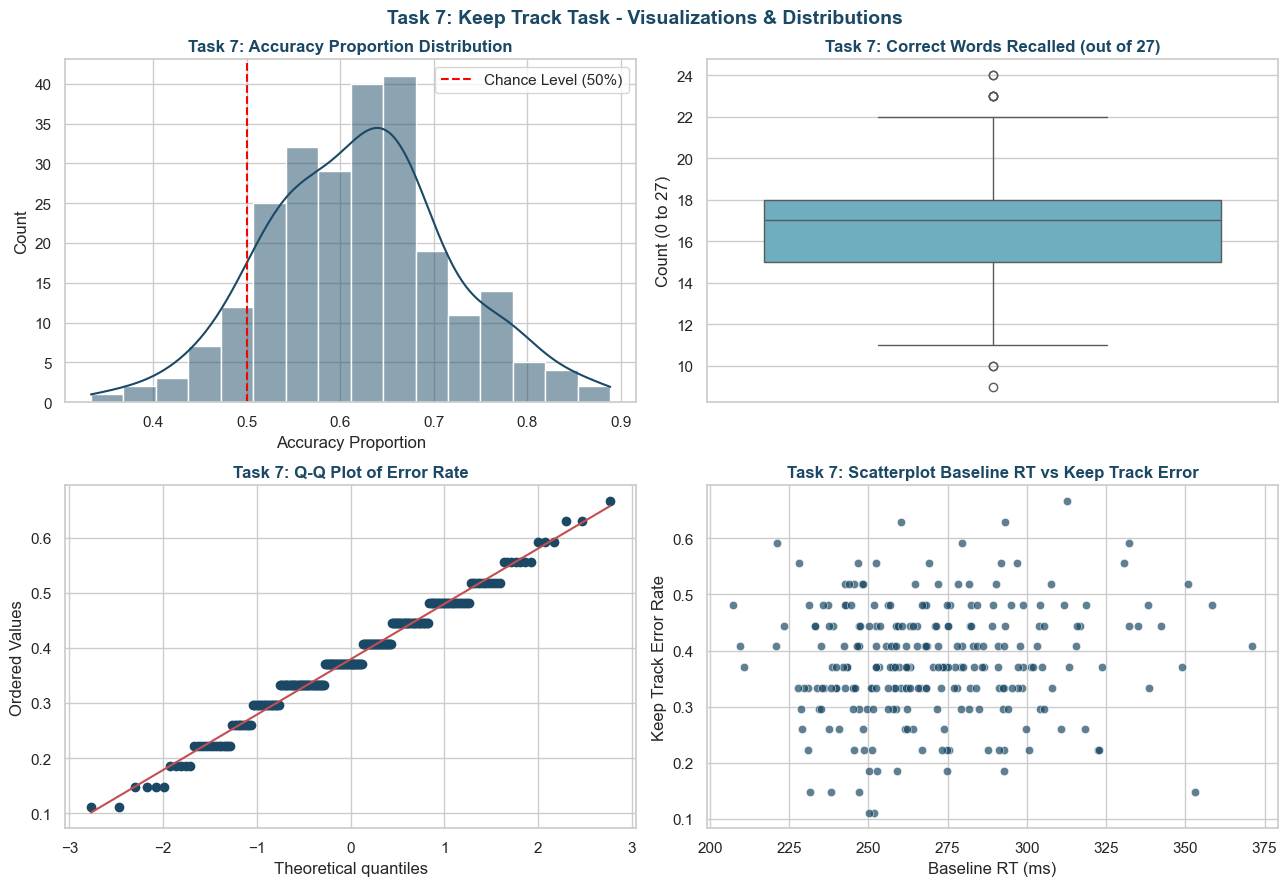

TASK 7: STATISTICAL ANALYSIS & NORMALITY TESTS
[Normality] Shapiro-Wilk (Error Rate): Stat = 0.9844, p-value = 8.2551e-03 | (< 0.05: True) -> Reject Normality
[Normality] Kolmogorov-Smirnov (Error Rate): Stat = 0.1008, p-value = 1.2282e-02 | (< 0.05: True) -> Reject Normality

[Comparison] One-sample t-test (Accuracy vs 50% Chance): t = 18.8640, p-value = 1.0634e-49 | (< 0.05: True) -> Significantly Above Chance
[Comparison] Wilcoxon One-sample: W = 1505.5, p-value = 7.8296e-35 | (< 0.05: True) -> Significantly Above Chance
[Descriptives & CI] Mean Accuracy = 62.06% | 95% CI = [60.80%, 63.32%]


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Task 7: Keep Track Task - Visualizations & Distributions', fontsize=14, fontweight='bold', color=primary_color)


sns.histplot(df['KeepTrack_ACC'], kde=True, color=primary_color, ax=axes[0, 0])
axes[0, 0].axvline(0.50, color='red', linestyle='--', label='Chance Level (50%)')
axes[0, 0].set_title('Task 7: Accuracy Proportion Distribution', fontweight='bold', color=primary_color)
axes[0, 0].set_xlabel('Accuracy Proportion')
axes[0, 0].legend()


sns.boxplot(y=df['KeepTrack_ACC_27'], color=secondary_color, ax=axes[0, 1])
axes[0, 1].set_title('Task 7: Correct Words Recalled (out of 27)', fontweight='bold', color=primary_color)
axes[0, 1].set_ylabel('Count (0 to 27)')


kt_err = df['KeepTrack_ERR'].dropna()
stats.probplot(kt_err, dist="norm", plot=axes[1, 0])
axes[1, 0].get_lines()[0].set_color(primary_color)
axes[1, 0].set_title('Task 7: Q-Q Plot of Error Rate', fontweight='bold', color=primary_color)


sns.scatterplot(x='RT_Mean_RT', y='KeepTrack_ERR', data=df, color=primary_color, alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title('Task 7: Scatterplot Baseline RT vs Keep Track Error', fontweight='bold', color=primary_color)
axes[1, 1].set_xlabel('Baseline RT (ms)')
axes[1, 1].set_ylabel('Keep Track Error Rate')

plt.tight_layout()
plt.show()


print("="*60)
print("TASK 7: STATISTICAL ANALYSIS & NORMALITY TESTS")
print("="*60)

shapiro_kt = stats.shapiro(kt_err)
std_kt = (kt_err - kt_err.mean()) / kt_err.std()
ks_kt = stats.kstest(std_kt, 'norm')

print(f"[Normality] Shapiro-Wilk (Error Rate): Stat = {shapiro_kt.statistic:.4f}, p-value = {shapiro_kt.pvalue:.4e} | (< 0.05: {shapiro_kt.pvalue < alpha}) -> {'Reject Normality' if shapiro_kt.pvalue < alpha else 'Fail to Reject Normality'}")
print(f"[Normality] Kolmogorov-Smirnov (Error Rate): Stat = {ks_kt.statistic:.4f}, p-value = {ks_kt.pvalue:.4e} | (< 0.05: {ks_kt.pvalue < alpha}) -> {'Reject Normality' if ks_kt.pvalue < alpha else 'Fail to Reject Normality'}")


ttest_chance = stats.ttest_1samp(df['KeepTrack_ACC'], 0.50)
wilcoxon_chance = stats.wilcoxon(df['KeepTrack_ACC'] - 0.50)

ci_kt = stats.t.interval(0.95, df=len(kt_err)-1, loc=np.mean(df['KeepTrack_ACC']), scale=stats.sem(df['KeepTrack_ACC']))

print(f"\n[Comparison] One-sample t-test (Accuracy vs 50% Chance): t = {ttest_chance.statistic:.4f}, p-value = {ttest_chance.pvalue:.4e} | (< 0.05: {ttest_chance.pvalue < alpha}) -> Significantly Above Chance")
print(f"[Comparison] Wilcoxon One-sample: W = {wilcoxon_chance.statistic:.1f}, p-value = {wilcoxon_chance.pvalue:.4e} | (< 0.05: {wilcoxon_chance.pvalue < alpha}) -> Significantly Above Chance")
print(f"[Descriptives & CI] Mean Accuracy = {np.mean(df['KeepTrack_ACC'])*100:.2f}% | 95% CI = [{ci_kt[0]*100:.2f}%, {ci_kt[1]*100:.2f}%]")

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\669836599.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['Keep Track Error', 'Letter Memory Error'])


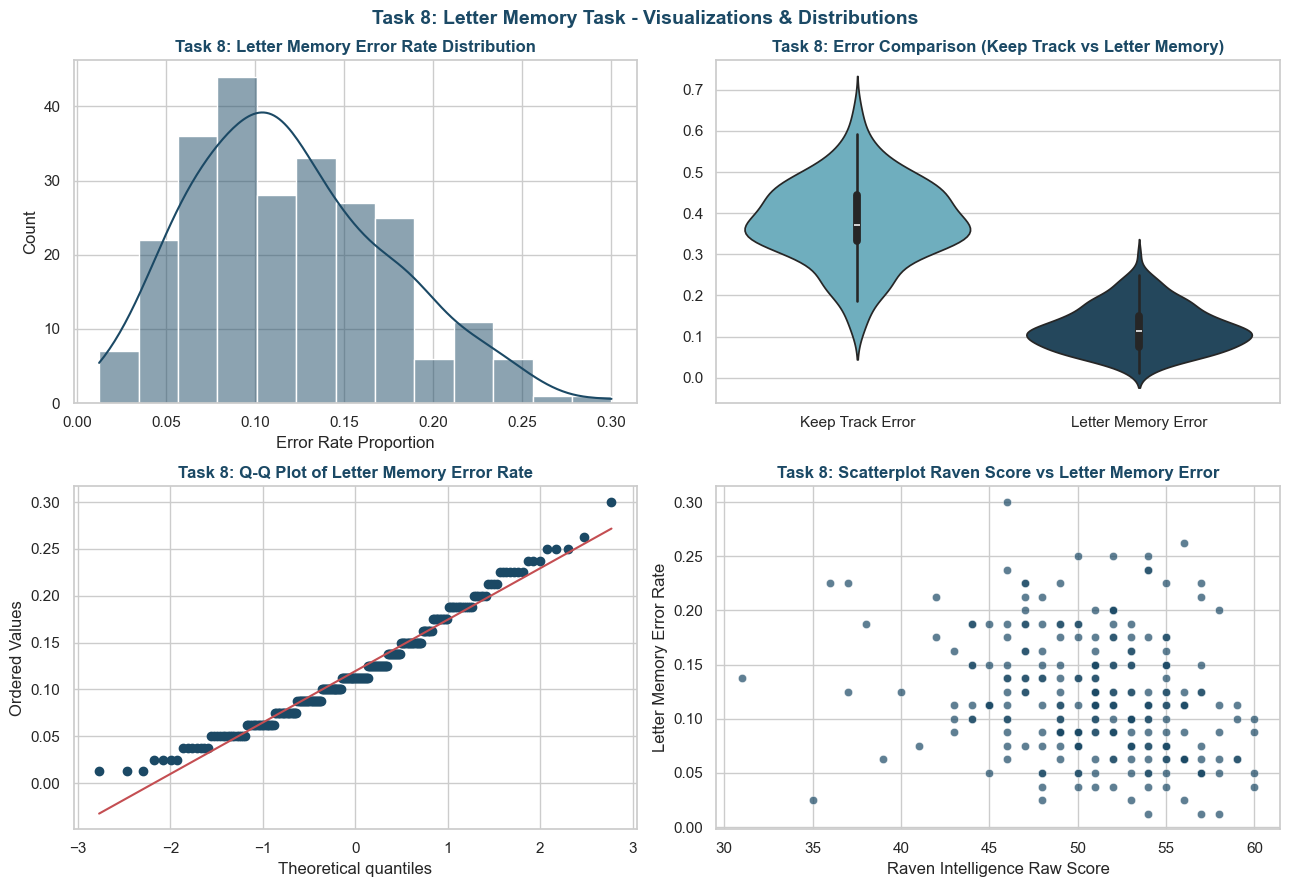

TASK 8: STATISTICAL ANALYSIS & NORMALITY TESTS
[Normality] Shapiro-Wilk (Error Rate): Stat = 0.9738, p-value = 1.6018e-04 | (< 0.05: True) -> Reject Normality
[Normality] Kolmogorov-Smirnov (Error Rate): Stat = 0.1053, p-value = 7.6838e-03 | (< 0.05: True) -> Reject Normality

[Comparison] Paired t-test (Keep Track ERR vs Letter Memory ERR): t = 40.9412, p-value = 8.1987e-112 | (< 0.05: True) -> Significant Difference
[Comparison] Wilcoxon Signed-Rank: W = 6.0, p-value = 3.0743e-42 | (< 0.05: True) -> Significant Difference
[Descriptives & CI] Mean Error = 11.95% | 95% CI = [11.26%, 12.65%] | Cohen's d (KT - LM) = 2.6050


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Task 8: Letter Memory Task - Visualizations & Distributions', fontsize=14, fontweight='bold', color=primary_color)


sns.histplot(df['LetMem_ERR'], kde=True, color=primary_color, ax=axes[0, 0])
axes[0, 0].set_title('Task 8: Letter Memory Error Rate Distribution', fontweight='bold', color=primary_color)
axes[0, 0].set_xlabel('Error Rate Proportion')


sns.violinplot(data=df[['KeepTrack_ERR', 'LetMem_ERR']], palette=[secondary_color, primary_color], ax=axes[0, 1])
axes[0, 1].set_xticklabels(['Keep Track Error', 'Letter Memory Error'])
axes[0, 1].set_title('Task 8: Error Comparison (Keep Track vs Letter Memory)', fontweight='bold', color=primary_color)


lm_err = df['LetMem_ERR'].dropna()
stats.probplot(lm_err, dist="norm", plot=axes[1, 0])
axes[1, 0].get_lines()[0].set_color(primary_color)
axes[1, 0].set_title('Task 8: Q-Q Plot of Letter Memory Error Rate', fontweight='bold', color=primary_color)


sns.scatterplot(x='Raven_RawScore', y='LetMem_ERR', data=df, color=primary_color, alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title('Task 8: Scatterplot Raven Score vs Letter Memory Error', fontweight='bold', color=primary_color)
axes[1, 1].set_xlabel('Raven Intelligence Raw Score')
axes[1, 1].set_ylabel('Letter Memory Error Rate')

plt.tight_layout()
plt.show()


print("="*60)
print("TASK 8: STATISTICAL ANALYSIS & NORMALITY TESTS")
print("="*60)

shapiro_lm = stats.shapiro(lm_err)
std_lm = (lm_err - lm_err.mean()) / lm_err.std()
ks_lm = stats.kstest(std_lm, 'norm')

print(f"[Normality] Shapiro-Wilk (Error Rate): Stat = {shapiro_lm.statistic:.4f}, p-value = {shapiro_lm.pvalue:.4e} | (< 0.05: {shapiro_lm.pvalue < alpha}) -> {'Reject Normality' if shapiro_lm.pvalue < alpha else 'Fail to Reject Normality'}")
print(f"[Normality] Kolmogorov-Smirnov (Error Rate): Stat = {ks_lm.statistic:.4f}, p-value = {ks_lm.pvalue:.4e} | (< 0.05: {ks_lm.pvalue < alpha}) -> {'Reject Normality' if ks_lm.pvalue < alpha else 'Fail to Reject Normality'}")


ttest_updating = stats.ttest_rel(df['KeepTrack_ERR'], df['LetMem_ERR'])
wilcoxon_updating = stats.wilcoxon(df['KeepTrack_ERR'], df['LetMem_ERR'])

up_diff = df['KeepTrack_ERR'] - df['LetMem_ERR']
d_up = np.mean(up_diff) / np.std(up_diff, ddof=1)
ci_lm = stats.t.interval(0.95, df=len(lm_err)-1, loc=np.mean(lm_err), scale=stats.sem(lm_err))

print(f"\n[Comparison] Paired t-test (Keep Track ERR vs Letter Memory ERR): t = {ttest_updating.statistic:.4f}, p-value = {ttest_updating.pvalue:.4e} | (< 0.05: {ttest_updating.pvalue < alpha}) -> Significant Difference")
print(f"[Comparison] Wilcoxon Signed-Rank: W = {wilcoxon_updating.statistic:.1f}, p-value = {wilcoxon_updating.pvalue:.4e} | (< 0.05: {wilcoxon_updating.pvalue < alpha}) -> Significant Difference")
print(f"[Descriptives & CI] Mean Error = {np.mean(lm_err)*100:.2f}% | 95% CI = [{ci_lm[0]*100:.2f}%, {ci_lm[1]*100:.2f}%] | Cohen's d (KT - LM) = {d_up:.4f}")

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\2889712914.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['Hit ERR (Omission)', 'No-Hit ERR (False Alarm)'])


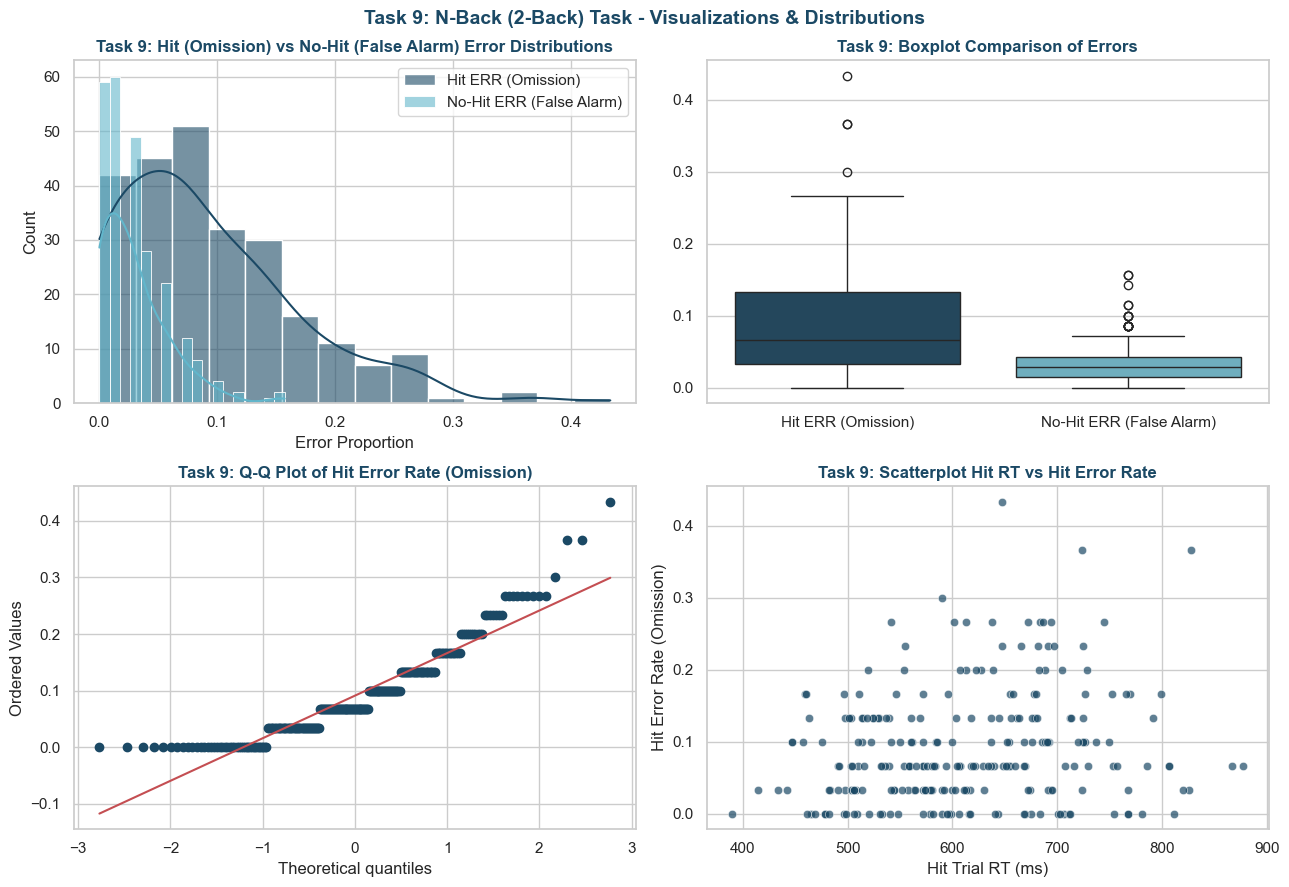

TASK 9: STATISTICAL ANALYSIS & NORMALITY TESTS
[Normality] Shapiro-Wilk (Hit Error): Stat = 0.8921, p-value = 2.7870e-12 | (< 0.05: True) -> Reject Normality
[Normality] Kolmogorov-Smirnov (Hit Error): Stat = 0.1793, p-value = 2.0166e-07 | (< 0.05: True) -> Reject Normality

[Comparison] Paired t-test (Hit ERR vs No-Hit ERR): t = 13.1654, p-value = 2.5481e-30 | (< 0.05: True) -> Significant Difference
[Comparison] Wilcoxon Signed-Rank: W = 1739.0, p-value = 2.9773e-30 | (< 0.05: True) -> Significant Difference
[Effect Size & CI] Mean Error Diff = 6.12% | Cohen's d = 0.8377


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Task 9: N-Back (2-Back) Task - Visualizations & Distributions', fontsize=14, fontweight='bold', color=primary_color)


sns.histplot(df['nBack_Mean_ERR_Hit'], kde=True, color=primary_color, label='Hit ERR (Omission)', ax=axes[0, 0], alpha=0.6)
sns.histplot(df['nBack_Mean_ERR_No_Hit'], kde=True, color=secondary_color, label='No-Hit ERR (False Alarm)', ax=axes[0, 0], alpha=0.6)
axes[0, 0].set_title('Task 9: Hit (Omission) vs No-Hit (False Alarm) Error Distributions', fontweight='bold', color=primary_color)
axes[0, 0].set_xlabel('Error Proportion')
axes[0, 0].legend()


sns.boxplot(data=df[['nBack_Mean_ERR_Hit', 'nBack_Mean_ERR_No_Hit']], palette=[primary_color, secondary_color], ax=axes[0, 1])
axes[0, 1].set_xticklabels(['Hit ERR (Omission)', 'No-Hit ERR (False Alarm)'])
axes[0, 1].set_title('Task 9: Boxplot Comparison of Errors', fontweight='bold', color=primary_color)


nb_hit_err = df['nBack_Mean_ERR_Hit'].dropna()
stats.probplot(nb_hit_err, dist="norm", plot=axes[1, 0])
axes[1, 0].get_lines()[0].set_color(primary_color)
axes[1, 0].set_title('Task 9: Q-Q Plot of Hit Error Rate (Omission)', fontweight='bold', color=primary_color)


sns.scatterplot(x='nBack_Mean_RT_Hit', y='nBack_Mean_ERR_Hit', data=df, color=primary_color, alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title('Task 9: Scatterplot Hit RT vs Hit Error Rate', fontweight='bold', color=primary_color)
axes[1, 1].set_xlabel('Hit Trial RT (ms)')
axes[1, 1].set_ylabel('Hit Error Rate (Omission)')

plt.tight_layout()
plt.show()


print("="*60)
print("TASK 9: STATISTICAL ANALYSIS & NORMALITY TESTS")
print("="*60)

shapiro_nb = stats.shapiro(nb_hit_err)
std_nb = (nb_hit_err - nb_hit_err.mean()) / nb_hit_err.std()
ks_nb = stats.kstest(std_nb, 'norm')

print(f"[Normality] Shapiro-Wilk (Hit Error): Stat = {shapiro_nb.statistic:.4f}, p-value = {shapiro_nb.pvalue:.4e} | (< 0.05: {shapiro_nb.pvalue < alpha}) -> {'Reject Normality' if shapiro_nb.pvalue < alpha else 'Fail to Reject Normality'}")
print(f"[Normality] Kolmogorov-Smirnov (Hit Error): Stat = {ks_nb.statistic:.4f}, p-value = {ks_nb.pvalue:.4e} | (< 0.05: {ks_nb.pvalue < alpha}) -> {'Reject Normality' if ks_nb.pvalue < alpha else 'Fail to Reject Normality'}")

ttest_nb = stats.ttest_rel(df['nBack_Mean_ERR_Hit'], df['nBack_Mean_ERR_No_Hit'])
wilcoxon_nb = stats.wilcoxon(df['nBack_Mean_ERR_Hit'], df['nBack_Mean_ERR_No_Hit'])

nb_diff = df['nBack_Mean_ERR_Hit'] - df['nBack_Mean_ERR_No_Hit']
d_nb = np.mean(nb_diff) / np.std(nb_diff, ddof=1)

print(f"\n[Comparison] Paired t-test (Hit ERR vs No-Hit ERR): t = {ttest_nb.statistic:.4f}, p-value = {ttest_nb.pvalue:.4e} | (< 0.05: {ttest_nb.pvalue < alpha}) -> Significant Difference")
print(f"[Comparison] Wilcoxon Signed-Rank: W = {wilcoxon_nb.statistic:.1f}, p-value = {wilcoxon_nb.pvalue:.4e} | (< 0.05: {wilcoxon_nb.pvalue < alpha}) -> Significant Difference")
print(f"[Effect Size & CI] Mean Error Diff = {np.mean(nb_diff)*100:.2f}% | Cohen's d = {d_nb:.4f}")

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\2731890257.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['Mean RT', 'Median RT'])


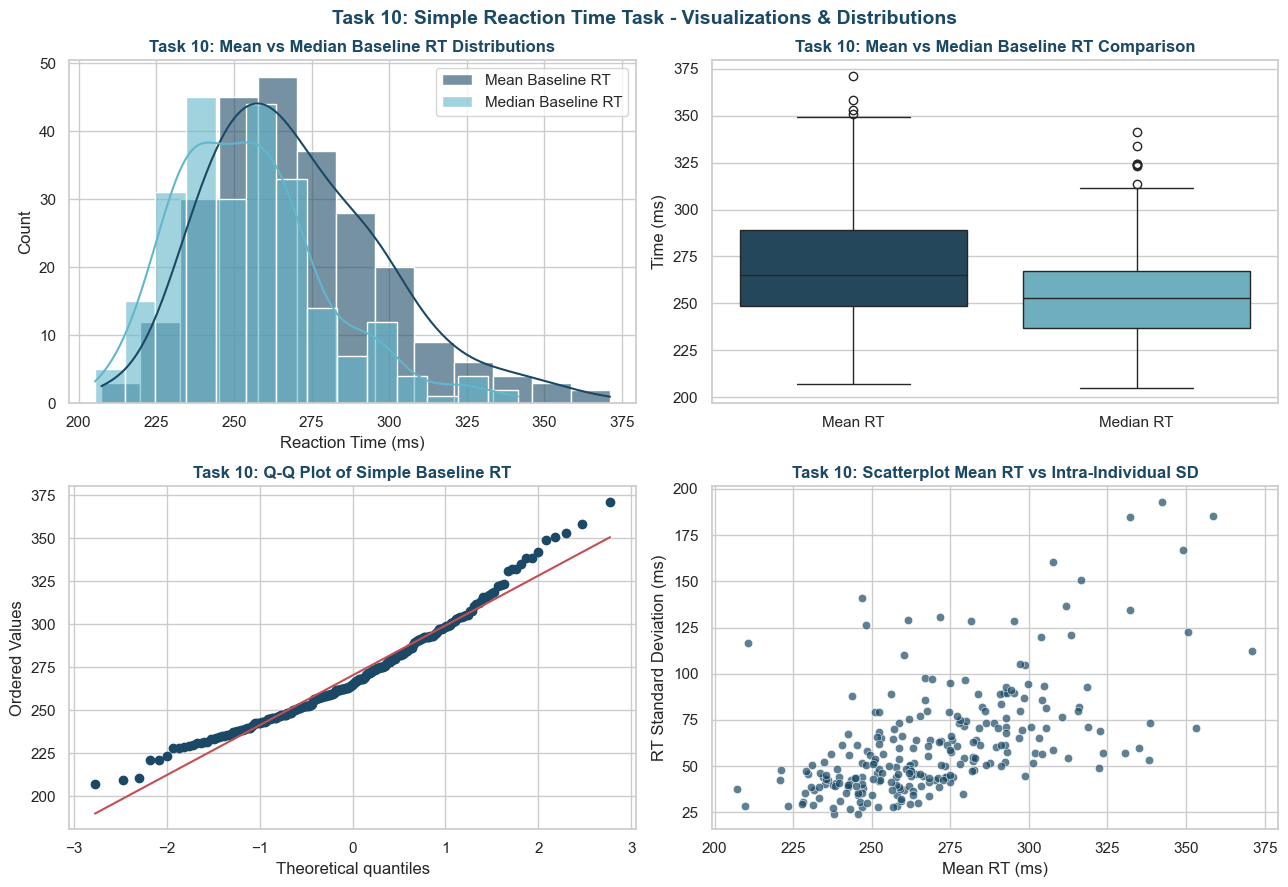

TASK 10: STATISTICAL ANALYSIS & NORMALITY TESTS
[Normality] Shapiro-Wilk (Simple RT): Stat = 0.9671, p-value = 1.8114e-05 | (< 0.05: True) -> Reject Normality
[Normality] Kolmogorov-Smirnov (Simple RT): Stat = 0.0795, p-value = 8.3100e-02 | (< 0.05: False) -> Fail to Reject Normality

[Comparison] Paired t-test (Mean RT vs Median RT): t = 22.2896, p-value = 5.7330e-61 | (< 0.05: True) -> Significant Skewness
[Comparison] Wilcoxon Signed-Rank: W = 197.0, p-value = 3.1150e-41 | (< 0.05: True) -> Significant Skewness
[Descriptives & CI] Mean Baseline RT = 270.25 ms | 95% CI = [266.58, 273.92] ms


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Task 10: Simple Reaction Time Task - Visualizations & Distributions', fontsize=14, fontweight='bold', color=primary_color)


sns.histplot(df['RT_Mean_RT'], kde=True, color=primary_color, label='Mean Baseline RT', ax=axes[0, 0], alpha=0.6)
sns.histplot(df['RT_Median_RT'], kde=True, color=secondary_color, label='Median Baseline RT', ax=axes[0, 0], alpha=0.6)
axes[0, 0].set_title('Task 10: Mean vs Median Baseline RT Distributions', fontweight='bold', color=primary_color)
axes[0, 0].set_xlabel('Reaction Time (ms)')
axes[0, 0].legend()


sns.boxplot(data=df[['RT_Mean_RT', 'RT_Median_RT']], palette=[primary_color, secondary_color], ax=axes[0, 1])
axes[0, 1].set_xticklabels(['Mean RT', 'Median RT'])
axes[0, 1].set_title('Task 10: Mean vs Median Baseline RT Comparison', fontweight='bold', color=primary_color)
axes[0, 1].set_ylabel('Time (ms)')


srt = df['RT_Mean_RT'].dropna()
stats.probplot(srt, dist="norm", plot=axes[1, 0])
axes[1, 0].get_lines()[0].set_color(primary_color)
axes[1, 0].set_title('Task 10: Q-Q Plot of Simple Baseline RT', fontweight='bold', color=primary_color)


sns.scatterplot(x='RT_Mean_RT', y='RT_SD_RT', data=df, color=primary_color, alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title('Task 10: Scatterplot Mean RT vs Intra-Individual SD', fontweight='bold', color=primary_color)
axes[1, 1].set_xlabel('Mean RT (ms)')
axes[1, 1].set_ylabel('RT Standard Deviation (ms)')

plt.tight_layout()
plt.show()


print("="*60)
print("TASK 10: STATISTICAL ANALYSIS & NORMALITY TESTS")
print("="*60)

shapiro_srt = stats.shapiro(srt)
std_srt = (srt - srt.mean()) / srt.std()
ks_srt = stats.kstest(std_srt, 'norm')

print(f"[Normality] Shapiro-Wilk (Simple RT): Stat = {shapiro_srt.statistic:.4f}, p-value = {shapiro_srt.pvalue:.4e} | (< 0.05: {shapiro_srt.pvalue < alpha}) -> {'Reject Normality' if shapiro_srt.pvalue < alpha else 'Fail to Reject Normality'}")
print(f"[Normality] Kolmogorov-Smirnov (Simple RT): Stat = {ks_srt.statistic:.4f}, p-value = {ks_srt.pvalue:.4e} | (< 0.05: {ks_srt.pvalue < alpha}) -> {'Reject Normality' if ks_srt.pvalue < alpha else 'Fail to Reject Normality'}")


ttest_mm = stats.ttest_rel(df['RT_Mean_RT'], df['RT_Median_RT'])
wilcoxon_mm = stats.wilcoxon(df['RT_Mean_RT'], df['RT_Median_RT'])

ci_srt = stats.t.interval(0.95, df=len(srt)-1, loc=np.mean(srt), scale=stats.sem(srt))

print(f"\n[Comparison] Paired t-test (Mean RT vs Median RT): t = {ttest_mm.statistic:.4f}, p-value = {ttest_mm.pvalue:.4e} | (< 0.05: {ttest_mm.pvalue < alpha}) -> Significant Skewness")
print(f"[Comparison] Wilcoxon Signed-Rank: W = {wilcoxon_mm.statistic:.1f}, p-value = {wilcoxon_mm.pvalue:.4e} | (< 0.05: {wilcoxon_mm.pvalue < alpha}) -> Significant Skewness")
print(f"[Descriptives & CI] Mean Baseline RT = {np.mean(srt):.2f} ms | 95% CI = [{ci_srt[0]:.2f}, {ci_srt[1]:.2f}] ms")

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\4166717811.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='BiologicalSex', data=df, palette=[primary_color, secondary_color], ax=axes[0, 0])
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\4166717811.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(['Male (0)', 'Female (1)'])
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\4166717811.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 2].set_xticklabels(['Normal Sleep', 'Sleep Today'])
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\4166717811.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and wi

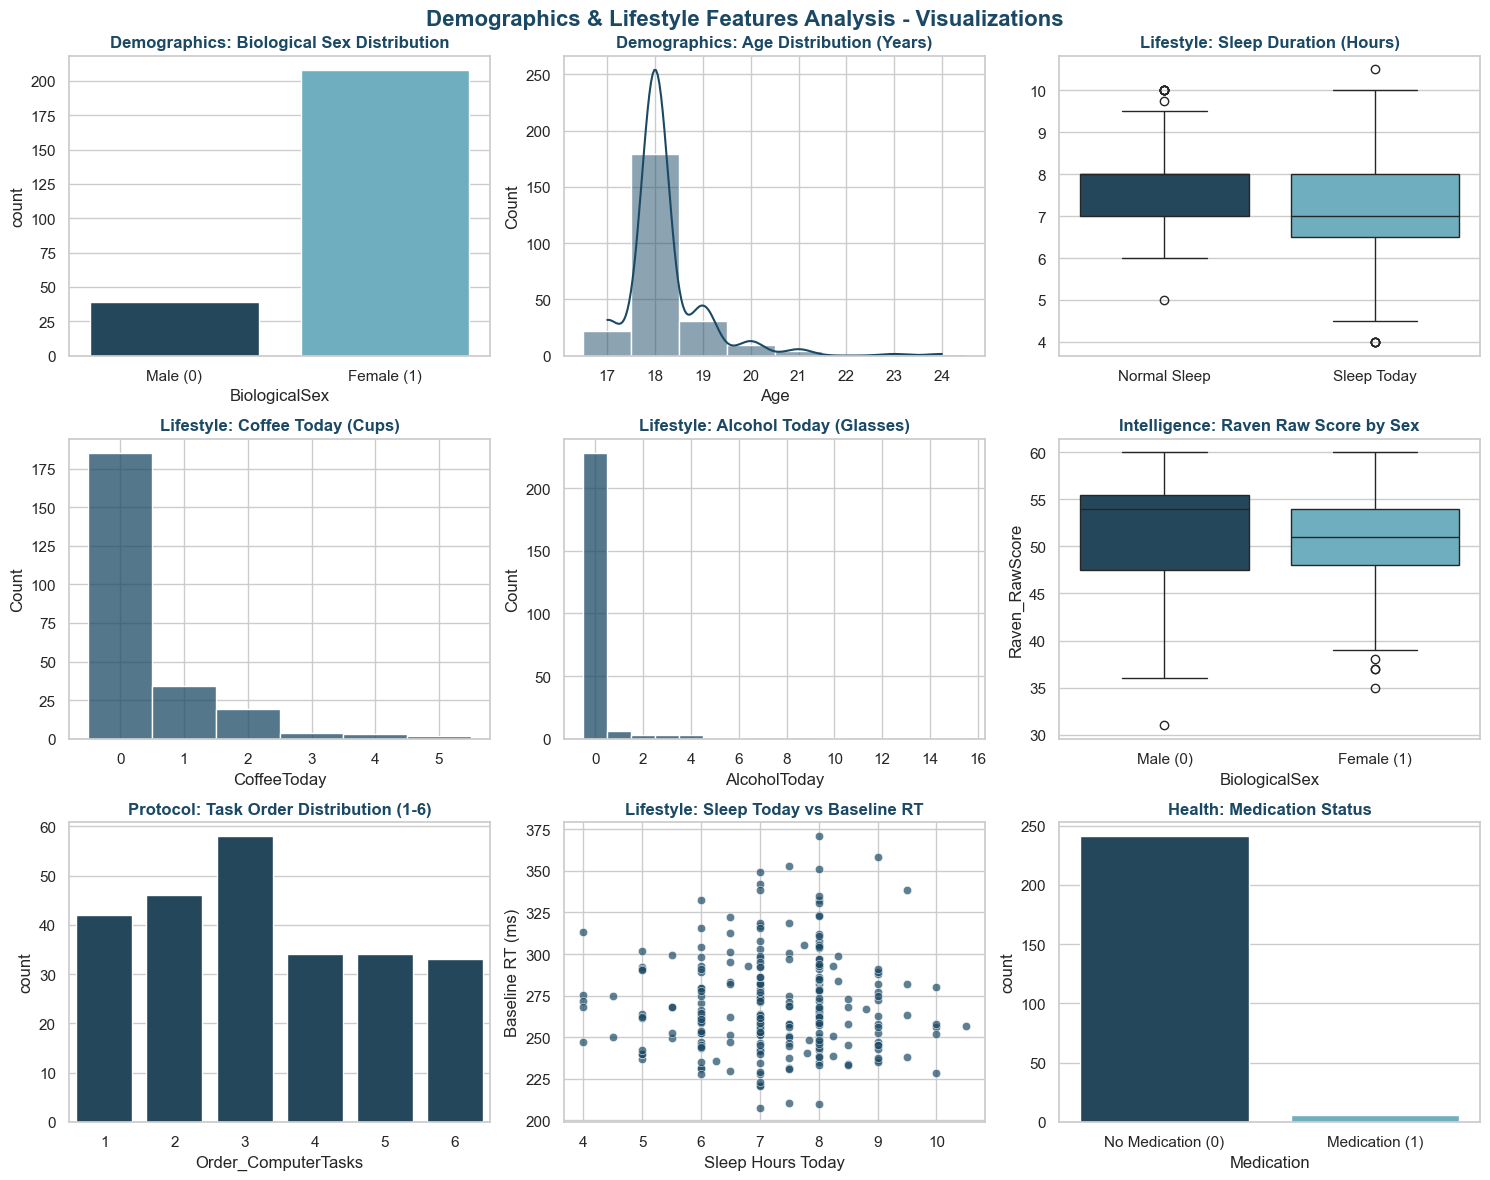

DEMOGRAPHICS & LIFESTYLE FEATURES: STATISTICAL ANALYSIS
[Sex vs Raven Score] Ind t-test: t = 1.4836, p-value = 1.3920e-01 | (< 0.05: False)
[Sex vs Raven Score] Mann-Whitney U: U = 5016.5, p-value = 1.8756e-02 | (< 0.05: True)

[Sleep vs Baseline RT] Pearson Correlation: r = 0.0141, p-value = 8.2594e-01 | (< 0.05: False)
[Sleep vs Baseline RT] Spearman Rank Correlation: rho = -0.0014, p-value = 9.8203e-01 | (< 0.05: False)

[Task Order vs Raven Score] One-Way ANOVA: F = 2.1141, p-value = 6.4430e-02 | (< 0.05: False) -> No Order Bias
[Task Order vs Raven Score] Kruskal-Wallis: H = 9.7706, p-value = 8.2001e-02 | (< 0.05: False) -> No Order Bias

[Sex vs High Raven] Chi-Square Test: Chi2 = 6.0296, p-value = 1.4068e-02 | (< 0.05: True)


In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle('Demographics & Lifestyle Features Analysis - Visualizations', fontsize=16, fontweight='bold', color=primary_color)


sns.countplot(x='BiologicalSex', data=df, palette=[primary_color, secondary_color], ax=axes[0, 0])
axes[0, 0].set_xticklabels(['Male (0)', 'Female (1)'])
axes[0, 0].set_title('Demographics: Biological Sex Distribution', fontweight='bold', color=primary_color)


sns.histplot(df['Age'], kde=True, color=primary_color, discrete=True, ax=axes[0, 1])
axes[0, 1].set_title('Demographics: Age Distribution (Years)', fontweight='bold', color=primary_color)


sns.boxplot(data=df[['SleepNormal', 'SleepToday']], palette=[primary_color, secondary_color], ax=axes[0, 2])
axes[0, 2].set_xticklabels(['Normal Sleep', 'Sleep Today'])
axes[0, 2].set_title('Lifestyle: Sleep Duration (Hours)', fontweight='bold', color=primary_color)


sns.histplot(df['CoffeeToday'], discrete=True, color=primary_color, ax=axes[1, 0])
axes[1, 0].set_title('Lifestyle: Coffee Today (Cups)', fontweight='bold', color=primary_color)


sns.histplot(df['AlcoholToday'], discrete=True, color=primary_color, ax=axes[1, 1])
axes[1, 1].set_title('Lifestyle: Alcohol Today (Glasses)', fontweight='bold', color=primary_color)


sns.boxplot(x='BiologicalSex', y='Raven_RawScore', data=df, palette=[primary_color, secondary_color], ax=axes[1, 2])
axes[1, 2].set_xticklabels(['Male (0)', 'Female (1)'])
axes[1, 2].set_title('Intelligence: Raven Raw Score by Sex', fontweight='bold', color=primary_color)


sns.countplot(x='Order_ComputerTasks', data=df, color=primary_color, ax=axes[2, 0])
axes[2, 0].set_title('Protocol: Task Order Distribution (1-6)', fontweight='bold', color=primary_color)


sns.scatterplot(x='SleepToday', y='RT_Mean_RT', data=df, color=primary_color, alpha=0.7, ax=axes[2, 1])
axes[2, 1].set_title('Lifestyle: Sleep Today vs Baseline RT', fontweight='bold', color=primary_color)
axes[2, 1].set_xlabel('Sleep Hours Today')
axes[2, 1].set_ylabel('Baseline RT (ms)')


sns.countplot(x='Medication', data=df, palette=[primary_color, secondary_color], ax=axes[2, 2])
axes[2, 2].set_xticklabels(['No Medication (0)', 'Medication (1)'])
axes[2, 2].set_title('Health: Medication Status', fontweight='bold', color=primary_color)

plt.tight_layout()
plt.show()


print("="*60)
print("DEMOGRAPHICS & LIFESTYLE FEATURES: STATISTICAL ANALYSIS")
print("="*60)


males_raven = df[df['BiologicalSex'] == 0]['Raven_RawScore'].dropna()
females_raven = df[df['BiologicalSex'] == 1]['Raven_RawScore'].dropna()

ttest_sex = stats.ttest_ind(males_raven, females_raven)
mwu_sex = stats.mannwhitneyu(males_raven, females_raven)

print(f"[Sex vs Raven Score] Ind t-test: t = {ttest_sex.statistic:.4f}, p-value = {ttest_sex.pvalue:.4e} | (< 0.05: {ttest_sex.pvalue < alpha})")
print(f"[Sex vs Raven Score] Mann-Whitney U: U = {mwu_sex.statistic:.1f}, p-value = {mwu_sex.pvalue:.4e} | (< 0.05: {mwu_sex.pvalue < alpha})")


r_sleep, p_sleep = stats.pearsonr(df['SleepToday'].dropna(), df['RT_Mean_RT'].dropna())
rho_sleep, p_rho_sleep = stats.spearmanr(df['SleepToday'].dropna(), df['RT_Mean_RT'].dropna())

print(f"\n[Sleep vs Baseline RT] Pearson Correlation: r = {r_sleep:.4f}, p-value = {p_sleep:.4e} | (< 0.05: {p_sleep < alpha})")
print(f"[Sleep vs Baseline RT] Spearman Rank Correlation: rho = {rho_sleep:.4f}, p-value = {p_rho_sleep:.4e} | (< 0.05: {p_rho_sleep < alpha})")


orders = [group['Raven_RawScore'].dropna() for name, group in df.groupby('Order_ComputerTasks')]
f_order, p_order = stats.f_oneway(*orders)
kw_order, p_kw_order = stats.kruskal(*orders)

print(f"\n[Task Order vs Raven Score] One-Way ANOVA: F = {f_order:.4f}, p-value = {p_order:.4e} | (< 0.05: {p_order < alpha}) -> No Order Bias")
print(f"[Task Order vs Raven Score] Kruskal-Wallis: H = {kw_order:.4f}, p-value = {p_kw_order:.4e} | (< 0.05: {p_kw_order < alpha}) -> No Order Bias")


df['High_Raven'] = df['Raven_RawScore'] > df['Raven_RawScore'].median()
contingency = pd.crosstab(df['BiologicalSex'], df['High_Raven'])
chi2, p_chi2, dof, _ = stats.chi2_contingency(contingency)

print(f"\n[Sex vs High Raven] Chi-Square Test: Chi2 = {chi2:.4f}, p-value = {p_chi2:.4e} | (< 0.05: {p_chi2 < alpha})")

## <span style="color: yellow; font-size: 40px;">***Part2***</span>

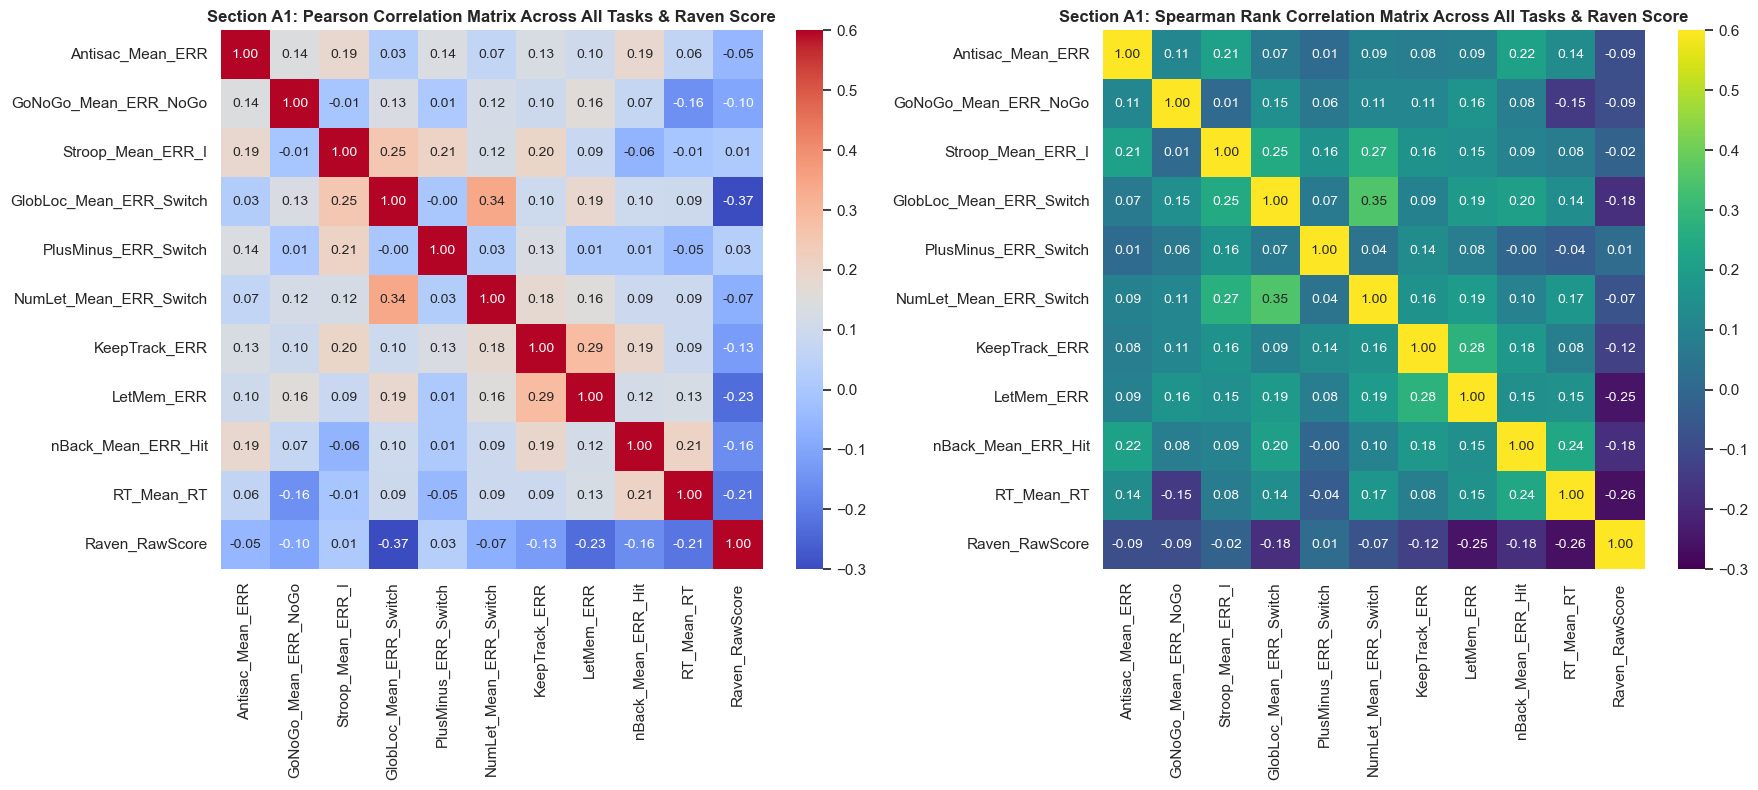

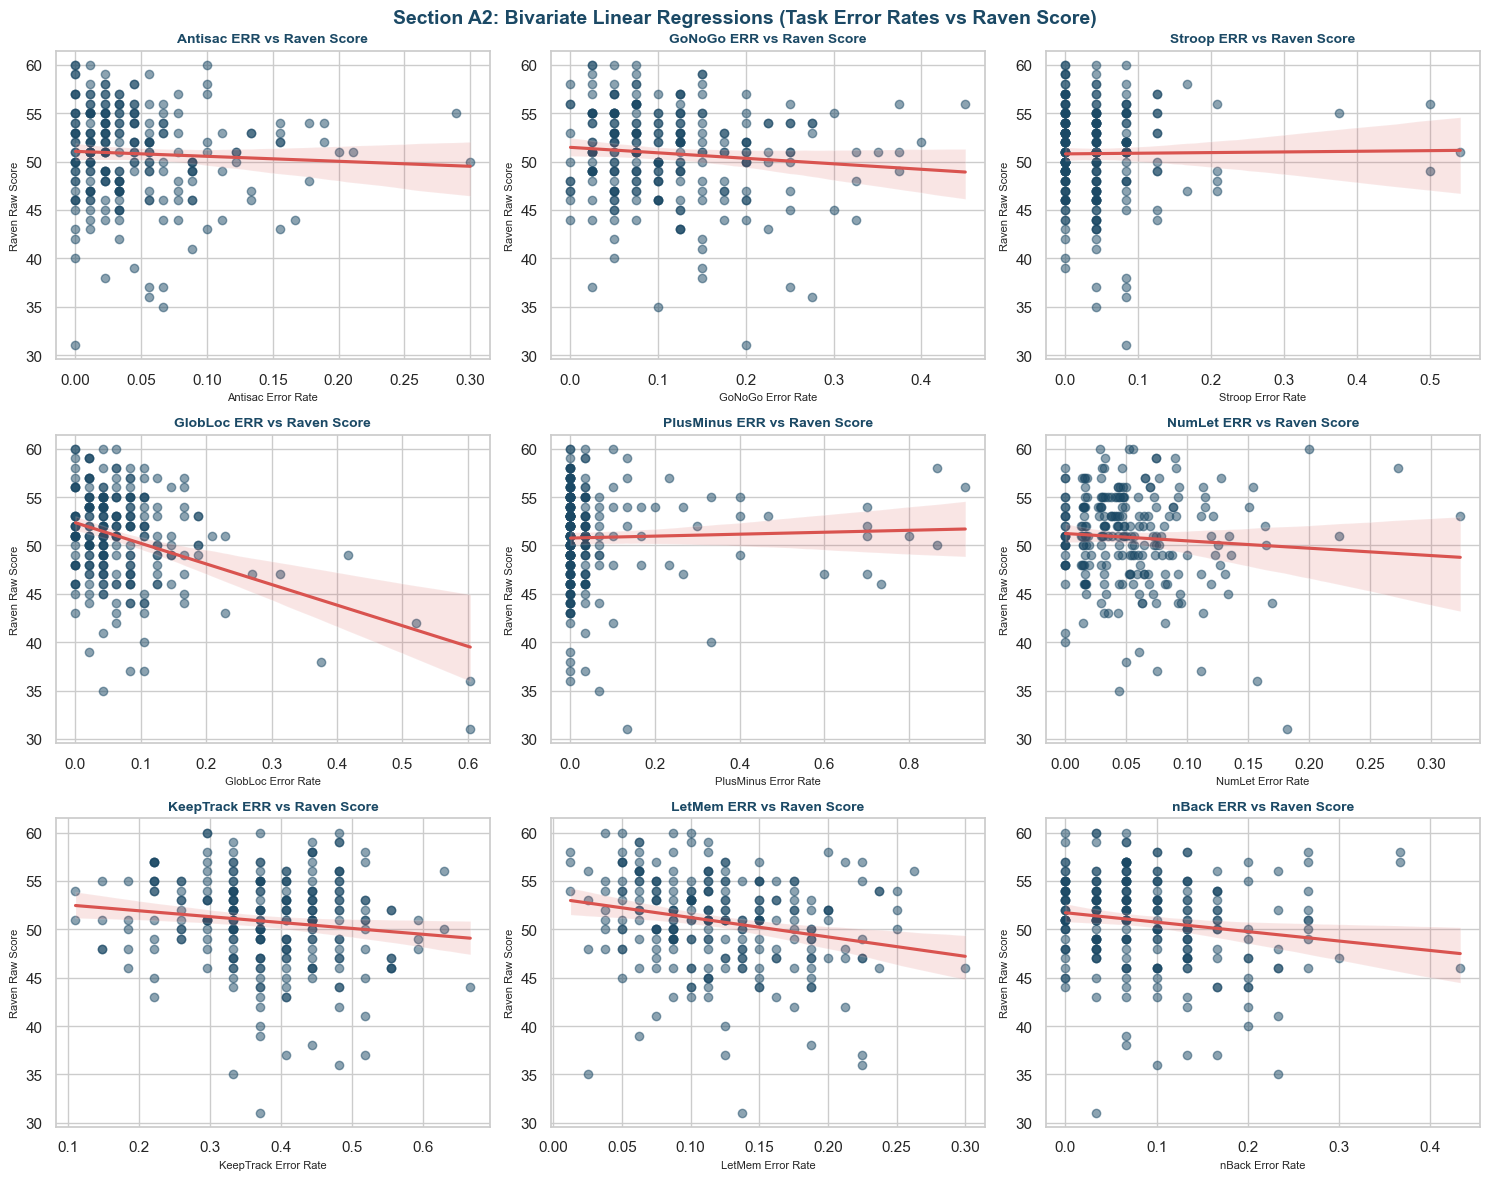

SECTION A: BIVARIATE REGRESSION & CORRELATION RESULTS
     Task  Pearson_r    p_pearson  p_pearson_sig  Spearman_rho  p_spearman       R2  Slope_p_val
  Antisac  -0.052523 4.111692e-01          False     -0.085435    0.180780 0.002759 4.111692e-01
   GoNoGo  -0.100158 1.163998e-01          False     -0.087939    0.168288 0.010032 1.163998e-01
   Stroop   0.009891 8.770808e-01          False     -0.018640    0.770677 0.000098 8.770808e-01
  GlobLoc  -0.369191 2.155243e-09           True     -0.177196    0.005224 0.136302 2.155243e-09
PlusMinus   0.033897 5.959820e-01          False      0.013073    0.838017 0.001149 5.959820e-01
   NumLet  -0.073617 2.490413e-01          False     -0.070061    0.272704 0.005419 2.490413e-01
KeepTrack  -0.126952 4.624488e-02           True     -0.124806    0.050089 0.016117 4.624488e-02
   LetMem  -0.230192 2.637497e-04           True     -0.251857    0.000063 0.052989 2.637497e-04
    nBack  -0.160196 1.169498e-02           True     -0.179427    0.00467

In [52]:
primary_err_cols = [
    'Antisac_Mean_ERR', 'GoNoGo_Mean_ERR_NoGo', 'Stroop_Mean_ERR_I',
    'GlobLoc_Mean_ERR_Switch', 'PlusMinus_ERR_Switch', 'NumLet_Mean_ERR_Switch',
    'KeepTrack_ERR', 'LetMem_ERR', 'nBack_Mean_ERR_Hit'
]

primary_all_cols = primary_err_cols + ['RT_Mean_RT', 'Raven_RawScore']

corr_pearson = df[primary_all_cols].corr(method='pearson')
corr_spearman = df[primary_all_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
sns.heatmap(corr_pearson, annot=True, cmap='coolwarm', vmin=-0.3, vmax=0.6, fmt='.2f', ax=axes[0])
axes[0].set_title('Section A1: Pearson Correlation Matrix Across All Tasks & Raven Score', fontweight='bold')

sns.heatmap(corr_spearman, annot=True, cmap='viridis', vmin=-0.3, vmax=0.6, fmt='.2f', ax=axes[1])
axes[1].set_title('Section A1: Spearman Rank Correlation Matrix Across All Tasks & Raven Score', fontweight='bold')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle('Section A2: Bivariate Linear Regressions (Task Error Rates vs Raven Score)', fontsize=14, fontweight='bold', color='#1b4965')

bivariate_results = []
for i, col in enumerate(primary_err_cols):
    row, c = divmod(i, 3)
    sns.regplot(x=col, y='Raven_RawScore', data=df, ax=axes[row, c],
                color='#1b4965', scatter_kws={'alpha': 0.5}, line_kws={'color': '#d9534f'})
    axes[row, c].set_title(f'{col.split("_")[0]} ERR vs Raven Score', fontsize=10, fontweight='bold', color='#1b4965')
    axes[row, c].set_xlabel(f'{col.split("_")[0]} Error Rate', fontsize=8)
    axes[row, c].set_ylabel('Raven Raw Score', fontsize=8)
    
    valid_df = df[[col, 'Raven_RawScore']].dropna()
    r_val, p_r = stats.pearsonr(valid_df[col], valid_df['Raven_RawScore'])
    rho_val, p_rho = stats.spearmanr(valid_df[col], valid_df['Raven_RawScore'])
    
    X_biv = sm.add_constant(valid_df[col])
    model_biv = sm.OLS(valid_df['Raven_RawScore'], X_biv).fit()
    
    bivariate_results.append({
        'Task': col.split('_')[0],
        'Pearson_r': r_val,
        'p_pearson': p_r,
        'p_pearson_sig': p_r < 0.05,
        'Spearman_rho': rho_val,
        'p_spearman': p_rho,
        'R2': model_biv.rsquared,
        'Slope_p_val': model_biv.pvalues.iloc[1]
    })

plt.tight_layout()
plt.show()

df_biv = pd.DataFrame(bivariate_results)
print("="*75)
print("SECTION A: BIVARIATE REGRESSION & CORRELATION RESULTS")
print("="*75)
print(df_biv.to_string(index=False))

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\3206712936.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='BiologicalSex', y=col, data=df, palette=['#1b4965', '#62b6cb'], ax=axes[row, c])
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\3206712936.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[row, c].set_xticklabels(['Male (0)', 'Female (1)'])
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\3206712936.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='BiologicalSex', y=col, data=df, palette=['#1b4965', '#62b6cb'], ax=axes[row, c])
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\3206712

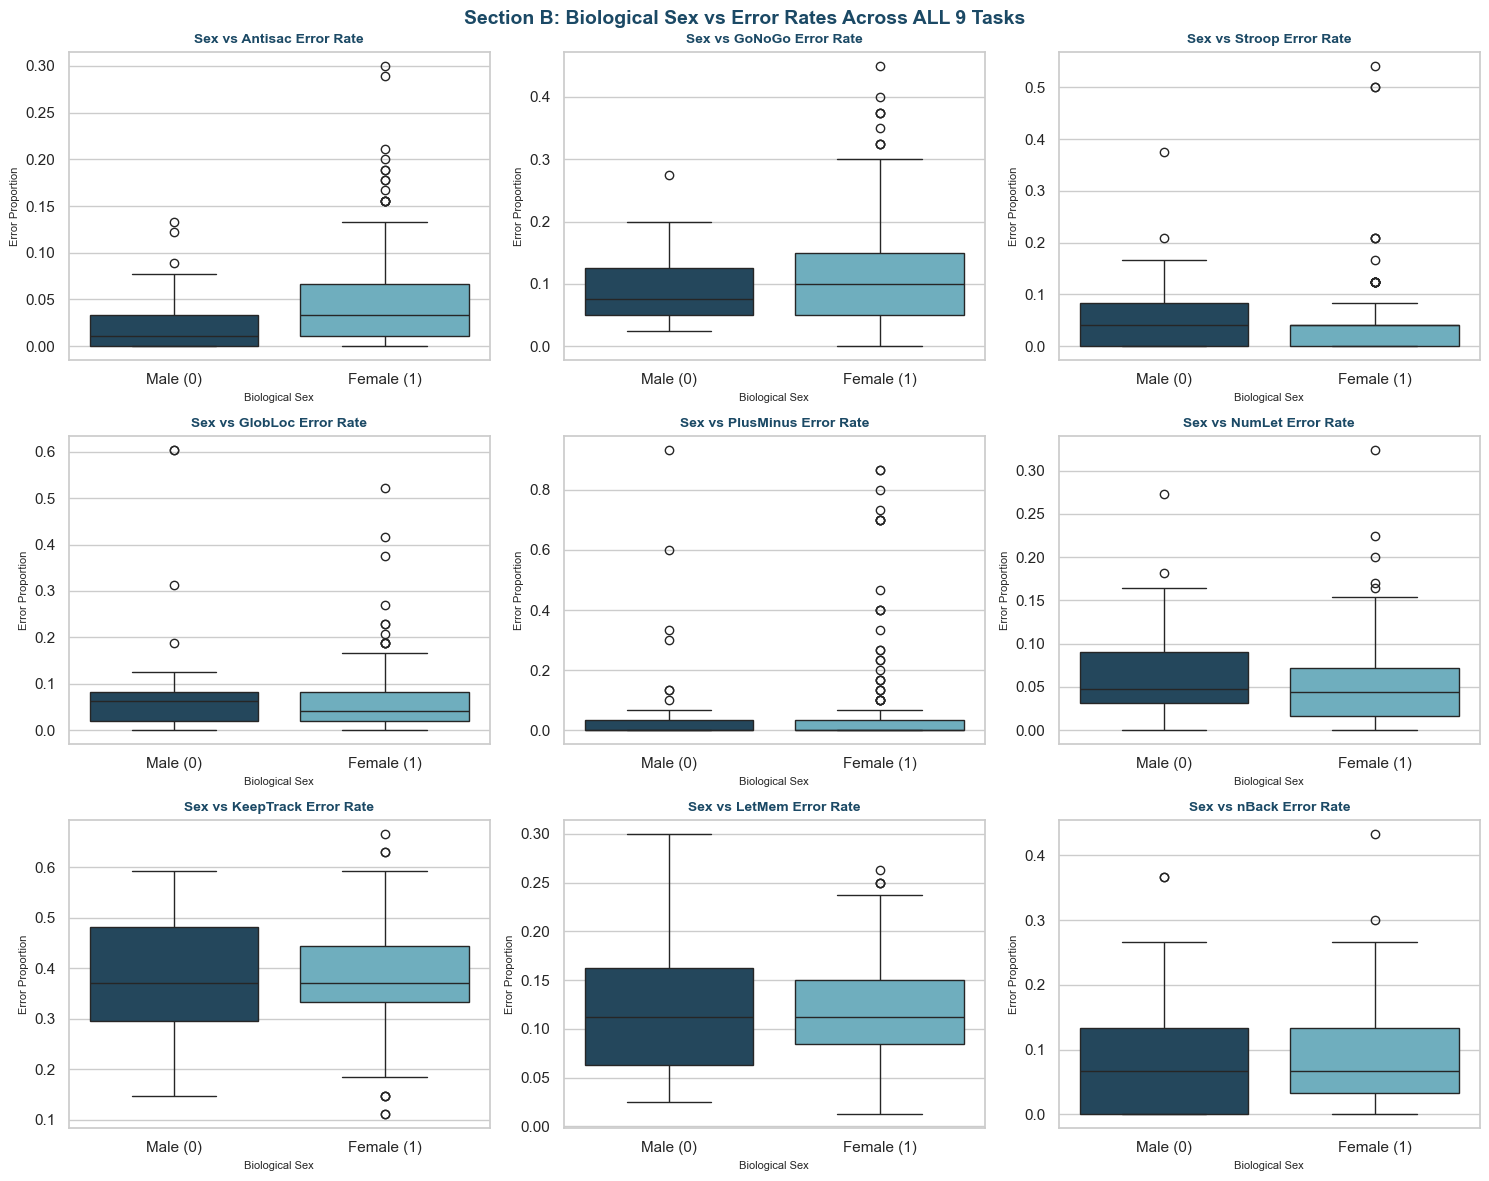

SECTION B: BIOLOGICAL SEX VS ALL TASK ERROR RATES STATISTICAL TESTS
     Task  Male_Mean_ERR  Female_Mean_ERR    t_stat      p_t  p_t_sig (<0.05)  u_stat      p_u  p_u_sig (<0.05)   Cohen_d  CI_95_Lower  CI_95_Upper
  Antisac       0.024216         0.048611 -2.887293 0.004233             True  2506.0 0.000137             True -0.503820    -0.036894    -0.011895
   GoNoGo       0.101282         0.115745 -0.975089 0.330478            False  3882.5 0.670598            False -0.170149    -0.037145     0.008219
   Stroop       0.049145         0.044872  0.343223 0.731725            False  4007.5 0.900853            False  0.059891    -0.021031     0.029578
  GlobLoc       0.091880         0.067508  1.678771 0.094472            False  4315.5 0.522564            False  0.292938    -0.018586     0.067331
PlusMinus       0.074359         0.061378  0.456293 0.648583            False  4238.5 0.613715            False  0.079621    -0.048470     0.074432
   NumLet       0.065478         0.050818  1

In [53]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle('Section B: Biological Sex vs Error Rates Across ALL 9 Tasks', fontsize=14, fontweight='bold', color='#1b4965')

sex_err_results = []
alpha = 0.05

for i, col in enumerate(primary_err_cols):
    row, c = divmod(i, 3)
    sns.boxplot(x='BiologicalSex', y=col, data=df, palette=['#1b4965', '#62b6cb'], ax=axes[row, c])
    axes[row, c].set_xticklabels(['Male (0)', 'Female (1)'])
    axes[row, c].set_title(f'Sex vs {col.split("_")[0]} Error Rate', fontsize=10, fontweight='bold', color='#1b4965')
    axes[row, c].set_xlabel('Biological Sex', fontsize=8)
    axes[row, c].set_ylabel('Error Proportion', fontsize=8)
    
    males = df[df['BiologicalSex'] == 0][col].dropna()
    females = df[df['BiologicalSex'] == 1][col].dropna()
    
    t_stat, p_t = stats.ttest_ind(males, females)
    u_stat, p_u = stats.mannwhitneyu(males, females)
    
    pooled_std = np.sqrt(((len(males)-1)*males.std()**2 + (len(females)-1)*females.std()**2) / (len(males)+len(females)-2))
    d_val = (males.mean() - females.mean()) / pooled_std
    
    diff_mean = males.mean() - females.mean()
    se_diff = np.sqrt(males.std()**2/len(males) + females.std()**2/len(females))
    ci_low = diff_mean - 1.96 * se_diff
    ci_upp = diff_mean + 1.96 * se_diff
    
    sex_err_results.append({
        'Task': col.split('_')[0],
        'Male_Mean_ERR': males.mean(),
        'Female_Mean_ERR': females.mean(),
        't_stat': t_stat,
        'p_t': p_t,
        'p_t_sig (<0.05)': p_t < alpha,
        'u_stat': u_stat,
        'p_u': p_u,
        'p_u_sig (<0.05)': p_u < alpha,
        'Cohen_d': d_val,
        'CI_95_Lower': ci_low,
        'CI_95_Upper': ci_upp
    })

plt.tight_layout()
plt.show()

df_sex_err = pd.DataFrame(sex_err_results)
print("="*85)
print("SECTION B: BIOLOGICAL SEX VS ALL TASK ERROR RATES STATISTICAL TESTS")
print("="*85)
print(df_sex_err.to_string(index=False))

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\955910773.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='BiologicalSex', y=col, data=df, palette=['#1b4965', '#62b6cb'], ax=axes[row, c])
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\955910773.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[row, c].set_xticklabels(['Male (0)', 'Female (1)'])
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\955910773.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='BiologicalSex', y=col, data=df, palette=['#1b4965', '#62b6cb'], ax=axes[row, c])
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\95591077

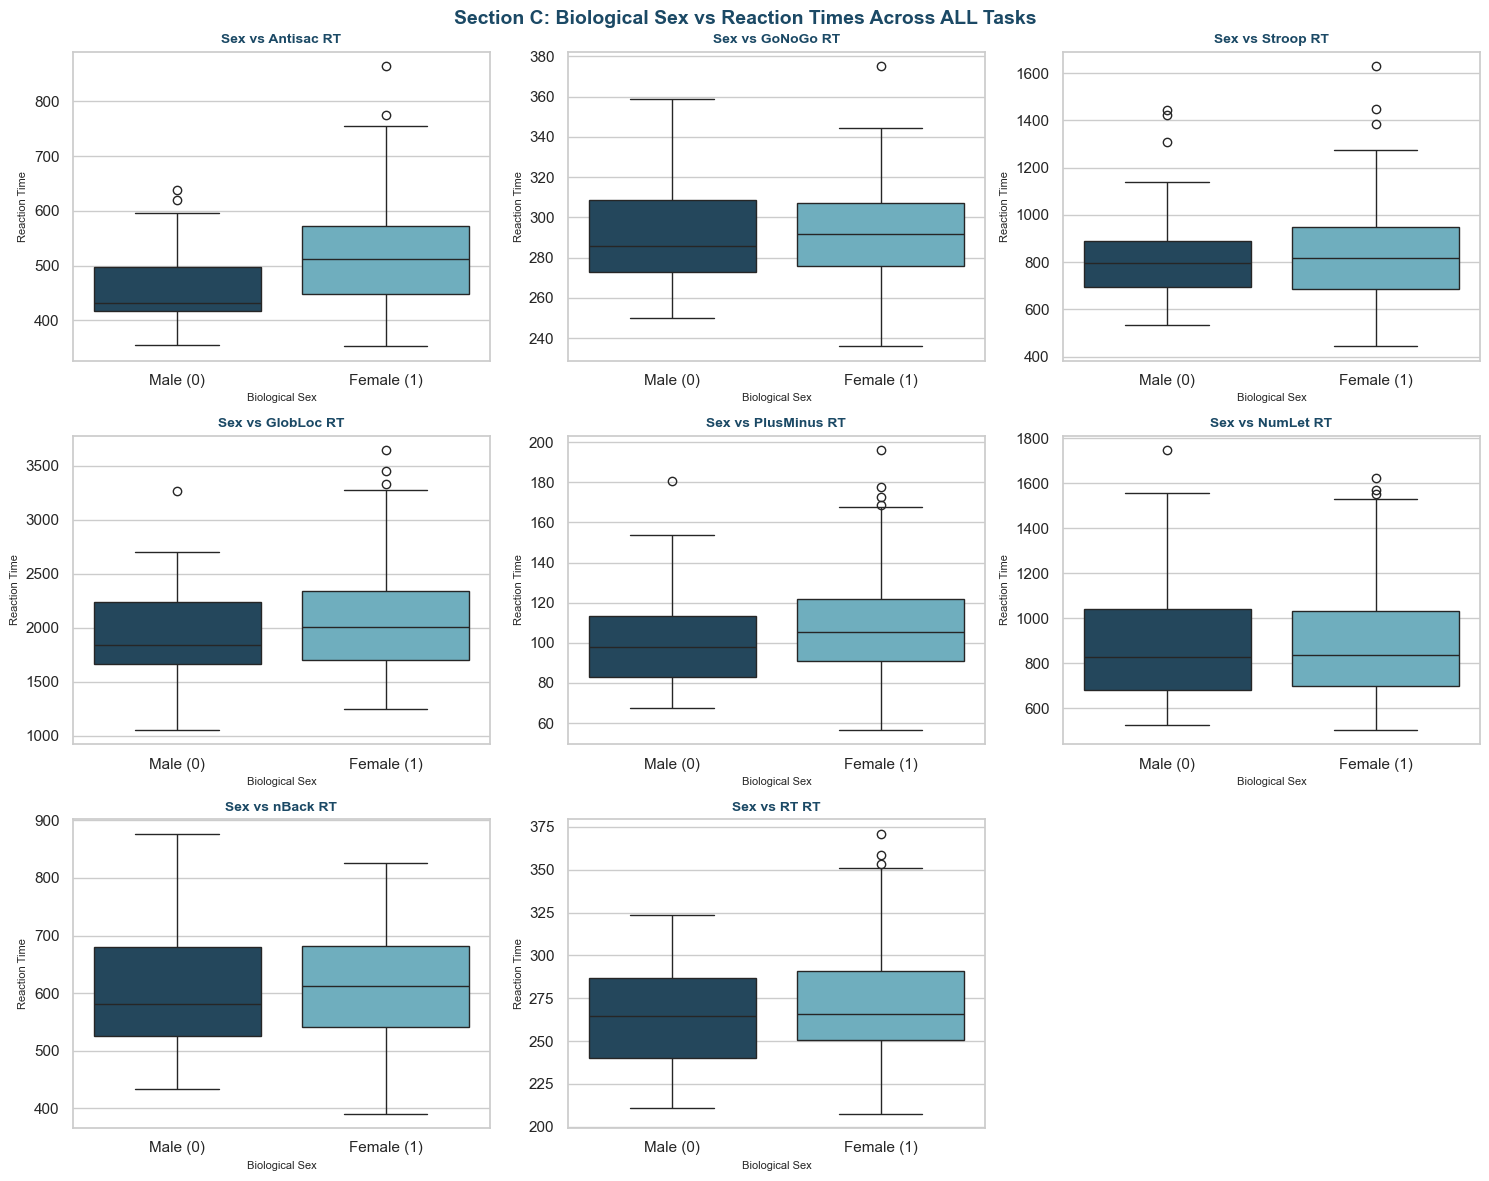

SECTION C: BIOLOGICAL SEX VS ALL REACTION TIMES STATISTICAL TESTS
     Task  Male_Mean_RT  Female_Mean_RT    t_stat      p_t  p_t_sig (<0.05)  u_stat      p_u  p_u_sig (<0.05)   Cohen_d  CI_95_Lower  CI_95_Upper
  Antisac    455.335240      515.114170 -4.124679 0.000051             True  2346.0 0.000030             True -0.719738   -85.553890   -34.003971
   GoNoGo    291.212813      291.760355 -0.131358 0.895600            False  3900.0 0.704109            False -0.022921    -8.737910     7.642825
   Stroop    828.263578      832.696007 -0.125084 0.900560            False  3834.0 0.588527            False -0.021827   -77.624772    68.759913
  GlobLoc   1969.921380     2071.928180 -1.235001 0.218013            False  3607.0 0.273352            False -0.215502  -251.433564    47.419963
PlusMinus    102.985897      108.006346 -1.183092 0.237920            False  3502.0 0.176433            False -0.206444   -13.677228     3.636331
   NumLet    879.235869      878.917955  0.007510 0.994014

In [54]:
primary_rt_cols = [
    'Antisac_Mean_RT', 'GoNoGo_Mean_RT_Go', 'Stroop_Mean_RT_I',
    'GlobLoc_Mean_RT_Switch', 'PlusMinus_Time_Switch', 'NumLet_Mean_RT_Switch',
    'nBack_Mean_RT_Hit', 'RT_Mean_RT'
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle('Section C: Biological Sex vs Reaction Times Across ALL Tasks', fontsize=14, fontweight='bold', color='#1b4965')

sex_rt_results = []

for i, col in enumerate(primary_rt_cols):
    row, c = divmod(i, 3)
    sns.boxplot(x='BiologicalSex', y=col, data=df, palette=['#1b4965', '#62b6cb'], ax=axes[row, c])
    axes[row, c].set_xticklabels(['Male (0)', 'Female (1)'])
    axes[row, c].set_title(f'Sex vs {col.split("_")[0]} RT', fontsize=10, fontweight='bold', color='#1b4965')
    axes[row, c].set_xlabel('Biological Sex', fontsize=8)
    axes[row, c].set_ylabel('Reaction Time', fontsize=8)
    
    males = df[df['BiologicalSex'] == 0][col].dropna()
    females = df[df['BiologicalSex'] == 1][col].dropna()
    
    t_stat, p_t = stats.ttest_ind(males, females)
    u_stat, p_u = stats.mannwhitneyu(males, females)
    
    pooled_std = np.sqrt(((len(males)-1)*males.std()**2 + (len(females)-1)*females.std()**2) / (len(males)+len(females)-2))
    d_val = (males.mean() - females.mean()) / pooled_std
    
    diff_mean = males.mean() - females.mean()
    se_diff = np.sqrt(males.std()**2/len(males) + females.std()**2/len(females))
    ci_low = diff_mean - 1.96 * se_diff
    ci_upp = diff_mean + 1.96 * se_diff
    
    sex_rt_results.append({
        'Task': col.split('_')[0],
        'Male_Mean_RT': males.mean(),
        'Female_Mean_RT': females.mean(),
        't_stat': t_stat,
        'p_t': p_t,
        'p_t_sig (<0.05)': p_t < alpha,
        'u_stat': u_stat,
        'p_u': p_u,
        'p_u_sig (<0.05)': p_u < alpha,
        'Cohen_d': d_val,
        'CI_95_Lower': ci_low,
        'CI_95_Upper': ci_upp
    })

axes[2, 2].axis('off')
plt.tight_layout()
plt.show()

df_sex_rt = pd.DataFrame(sex_rt_results)
print("="*85)
print("SECTION C: BIOLOGICAL SEX VS ALL REACTION TIMES STATISTICAL TESTS")
print("="*85)
print(df_sex_rt.to_string(index=False))

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\816299830.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sleep_groups = [g[col].dropna() for _, g in valid_data.groupby('SleepGroup')]
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\816299830.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sleep_groups = [g[col].dropna() for _, g in valid_data.groupby('SleepGroup')]
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\816299830.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or obser

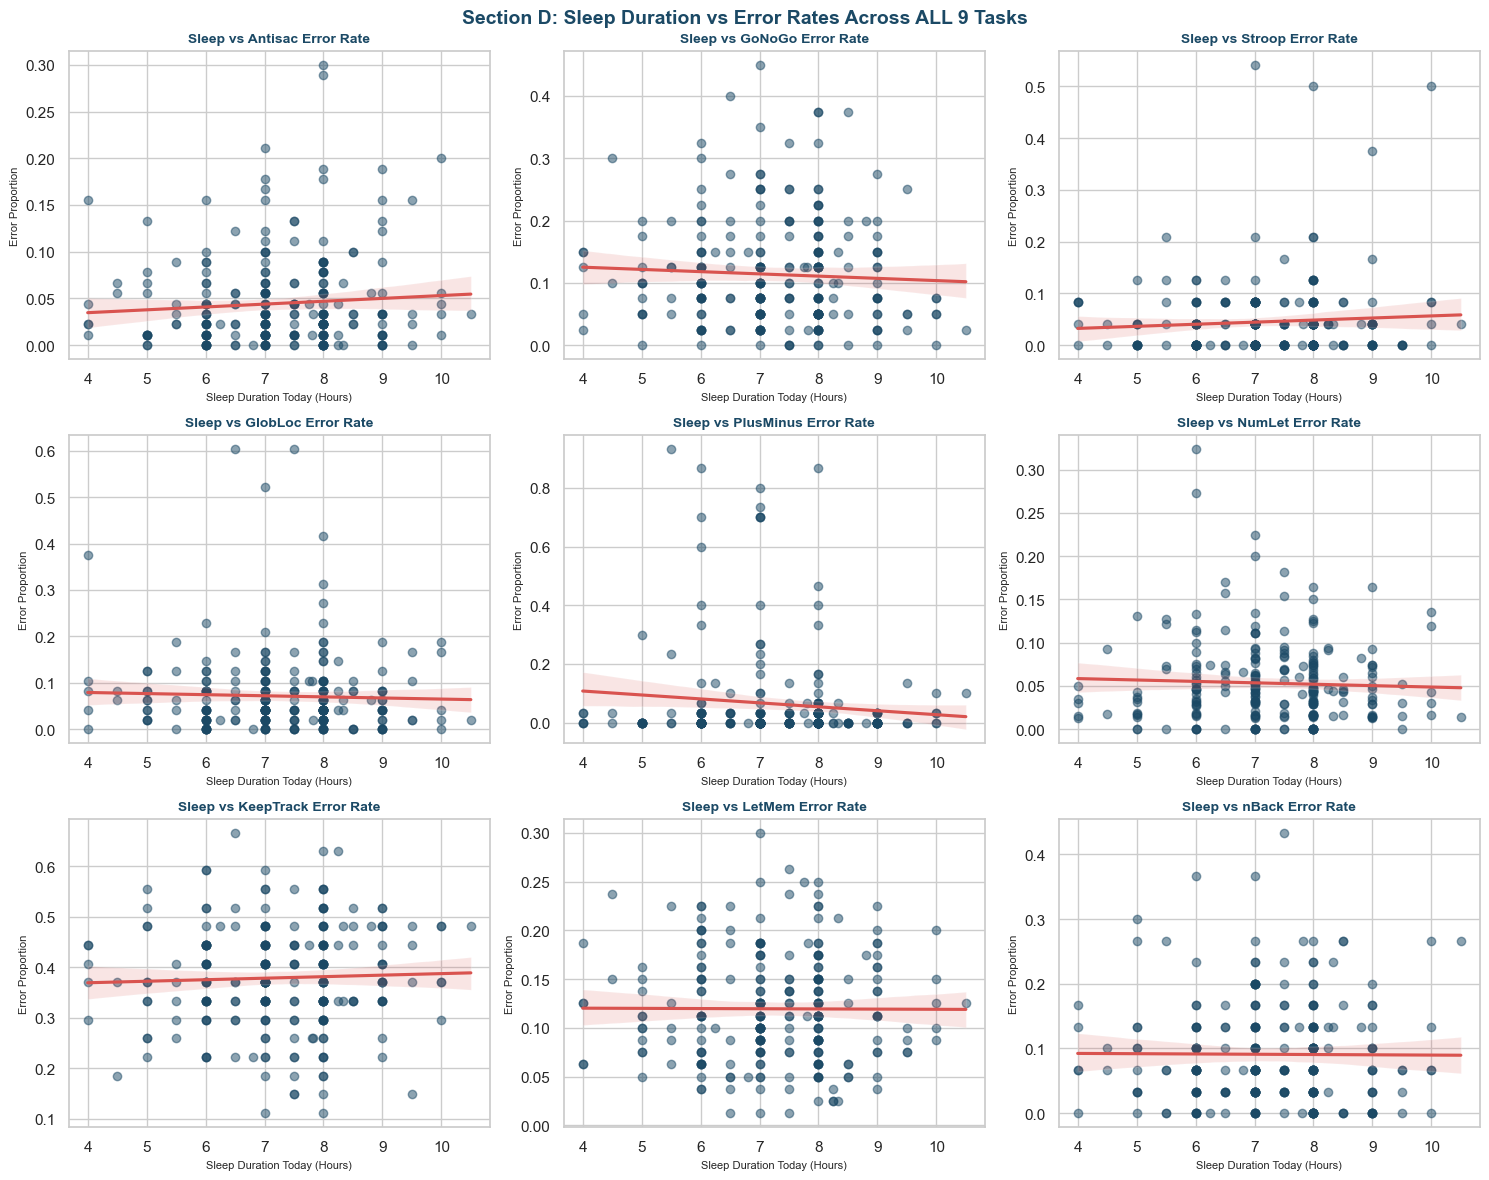

SECTION D: SLEEP DURATION VS ALL TASK ERROR RATES STATISTICAL TESTS
     Task  Pearson_r  p_pearson  p_pearson_sig  Spearman_rho  p_spearman  ANOVA_F  p_anova  p_anova_sig  Kruskal_H  p_kruskal
  Antisac   0.077508   0.224829          False      0.041209    0.519159 0.844213 0.431147        False   0.930188   0.628076
   GoNoGo  -0.052619   0.410312          False     -0.064343    0.313868 0.525025 0.592208        False   1.053630   0.590483
   Stroop   0.070431   0.270173          False     -0.013085    0.837874 0.389734 0.677658        False   0.391325   0.822290
  GlobLoc  -0.035326   0.580569          False     -0.032254    0.613928 1.151147 0.317985        False   1.355463   0.507767
PlusMinus  -0.102945   0.106528          False     -0.041080    0.520474 2.449419 0.088464        False   3.400268   0.182659
   NumLet  -0.043518   0.496001          False     -0.050935    0.425477 0.255693 0.774587        False   0.746373   0.688537
KeepTrack   0.037461   0.557899          False    

In [55]:
df['SleepGroup'] = pd.cut(df['SleepToday'], bins=[-1, 6, 8, 24], labels=['Low (<6h)', 'Normal (6-8h)', 'High (>8h)'])

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle('Section D: Sleep Duration vs Error Rates Across ALL 9 Tasks', fontsize=14, fontweight='bold', color='#1b4965')

sleep_err_results = []

for i, col in enumerate(primary_err_cols):
    row, c = divmod(i, 3)
    sns.regplot(x='SleepToday', y=col, data=df, ax=axes[row, c],
                color='#1b4965', scatter_kws={'alpha': 0.5}, line_kws={'color': '#d9534f'})
    axes[row, c].set_title(f'Sleep vs {col.split("_")[0]} Error Rate', fontsize=10, fontweight='bold', color='#1b4965')
    axes[row, c].set_xlabel('Sleep Duration Today (Hours)', fontsize=8)
    axes[row, c].set_ylabel('Error Proportion', fontsize=8)
    
    valid_data = df[['SleepToday', 'SleepGroup', col]].dropna()
    r_val, p_r = stats.pearsonr(valid_data['SleepToday'], valid_data[col])
    rho_val, p_rho = stats.spearmanr(valid_data['SleepToday'], valid_data[col])
    
    sleep_groups = [g[col].dropna() for _, g in valid_data.groupby('SleepGroup')]
    f_stat, p_f = stats.f_oneway(*sleep_groups)
    kw_stat, p_kw = stats.kruskal(*sleep_groups)
    
    sleep_err_results.append({
        'Task': col.split('_')[0],
        'Pearson_r': r_val,
        'p_pearson': p_r,
        'p_pearson_sig': p_r < alpha,
        'Spearman_rho': rho_val,
        'p_spearman': p_rho,
        'ANOVA_F': f_stat,
        'p_anova': p_f,
        'p_anova_sig': p_f < alpha,
        'Kruskal_H': kw_stat,
        'p_kruskal': p_kw
    })

plt.tight_layout()
plt.show()

df_sleep_err = pd.DataFrame(sleep_err_results)
print("="*85)
print("SECTION D: SLEEP DURATION VS ALL TASK ERROR RATES STATISTICAL TESTS")
print("="*85)
print(df_sleep_err.to_string(index=False))

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\2559496024.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sleep_groups = [g[col].dropna() for _, g in valid_data.groupby('SleepGroup')]
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\2559496024.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sleep_groups = [g[col].dropna() for _, g in valid_data.groupby('SleepGroup')]
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\2559496024.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or ob

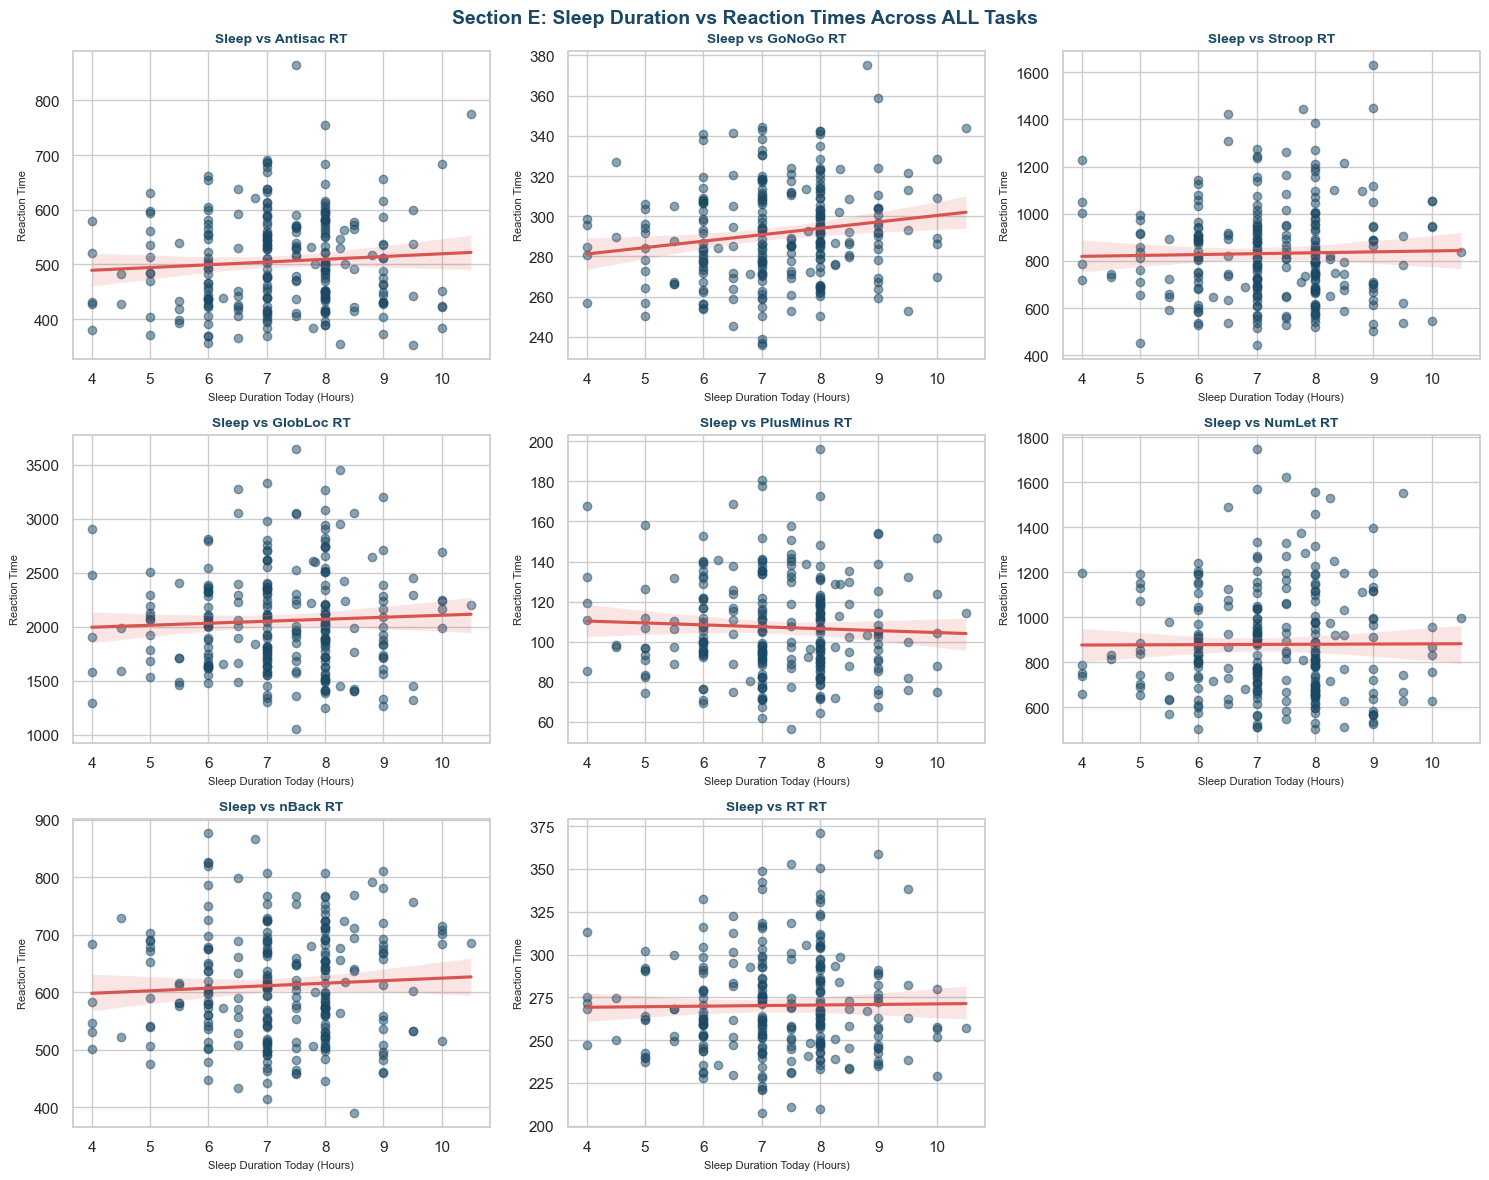

SECTION E: SLEEP DURATION VS ALL REACTION TIMES STATISTICAL TESTS
     Task  Pearson_r  p_pearson  p_pearson_sig  Spearman_rho  p_spearman  ANOVA_F  p_anova  p_anova_sig  Kruskal_H  p_kruskal
  Antisac   0.073170   0.251936          False      0.048440    0.448528 2.850394 0.059749        False   5.470591   0.064875
   GoNoGo   0.166894   0.008586           True      0.160714    0.011423 2.280836 0.104374        False   4.138678   0.126269
   Stroop   0.023425   0.714115          False     -0.006076    0.924305 0.135283 0.873534        False   0.030045   0.985090
  GlobLoc   0.048681   0.446270          False      0.023338    0.715125 0.695546 0.499788        False   0.676336   0.713076
PlusMinus  -0.049034   0.442977          False     -0.050041    0.433656 0.118326 0.888457        False   0.436206   0.804043
   NumLet   0.004558   0.943182          False     -0.035600    0.577642 0.151308 0.859664        False   0.059460   0.970708
    nBack   0.057622   0.367186          False      

In [56]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle('Section E: Sleep Duration vs Reaction Times Across ALL Tasks', fontsize=14, fontweight='bold', color='#1b4965')

sleep_rt_results = []

for i, col in enumerate(primary_rt_cols):
    row, c = divmod(i, 3)
    sns.regplot(x='SleepToday', y=col, data=df, ax=axes[row, c],
                color='#1b4965', scatter_kws={'alpha': 0.5}, line_kws={'color': '#d9534f'})
    axes[row, c].set_title(f'Sleep vs {col.split("_")[0]} RT', fontsize=10, fontweight='bold', color='#1b4965')
    axes[row, c].set_xlabel('Sleep Duration Today (Hours)', fontsize=8)
    axes[row, c].set_ylabel('Reaction Time', fontsize=8)
    
    valid_data = df[['SleepToday', 'SleepGroup', col]].dropna()
    r_val, p_r = stats.pearsonr(valid_data['SleepToday'], valid_data[col])
    rho_val, p_rho = stats.spearmanr(valid_data['SleepToday'], valid_data[col])
    
    sleep_groups = [g[col].dropna() for _, g in valid_data.groupby('SleepGroup')]
    f_stat, p_f = stats.f_oneway(*sleep_groups)
    kw_stat, p_kw = stats.kruskal(*sleep_groups)
    
    sleep_rt_results.append({
        'Task': col.split('_')[0],
        'Pearson_r': r_val,
        'p_pearson': p_r,
        'p_pearson_sig': p_r < alpha,
        'Spearman_rho': rho_val,
        'p_spearman': p_rho,
        'ANOVA_F': f_stat,
        'p_anova': p_f,
        'p_anova_sig': p_f < alpha,
        'Kruskal_H': kw_stat,
        'p_kruskal': p_kw
    })

axes[2, 2].axis('off')
plt.tight_layout()
plt.show()

df_sleep_rt = pd.DataFrame(sleep_rt_results)
print("="*85)
print("SECTION E: SLEEP DURATION VS ALL REACTION TIMES STATISTICAL TESTS")
print("="*85)
print(df_sleep_rt.to_string(index=False))

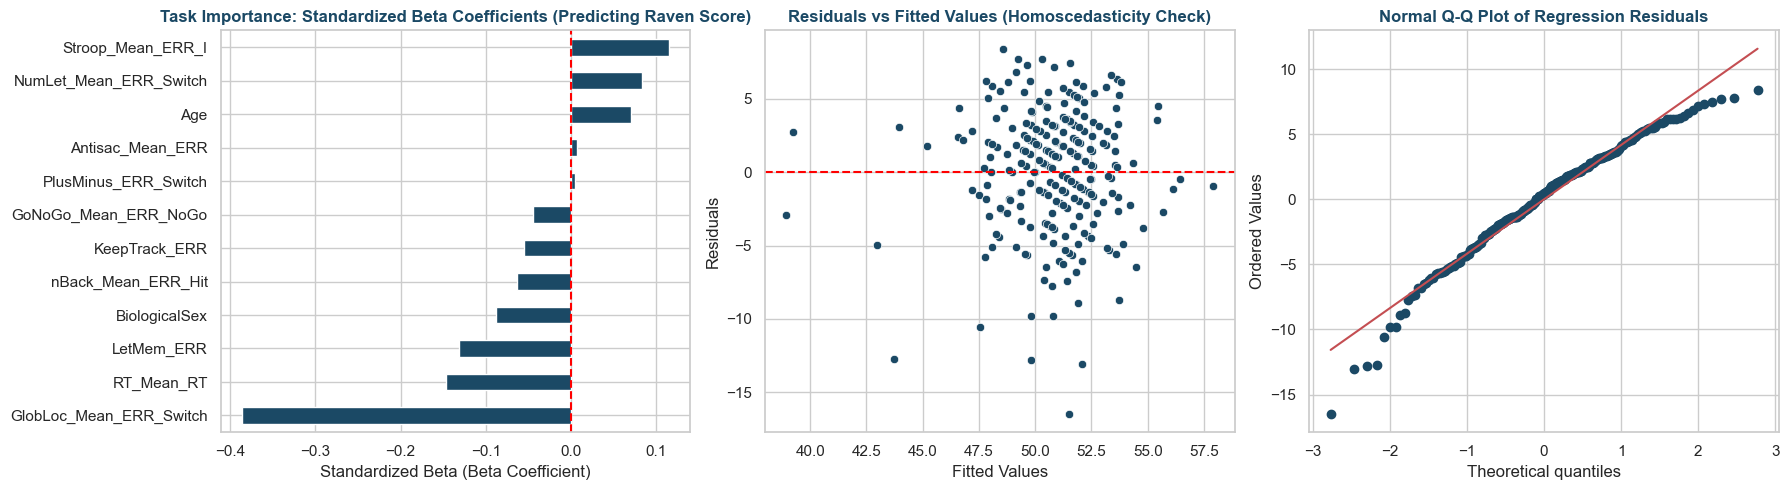

SECTION F: MULTIPLE LINEAR REGRESSION & TASK IMPORTANCE RESULTS
                            OLS Regression Results                            
Dep. Variable:         Raven_RawScore   R-squared:                       0.235
Model:                            OLS   Adj. R-squared:                  0.196
Method:                 Least Squares   F-statistic:                     5.989
Date:                Wed, 29 Jul 2026   Prob (F-statistic):           4.22e-09
Time:                        23:23:41   Log-Likelihood:                -704.82
No. Observations:                 247   AIC:                             1436.
Df Residuals:                     234   BIC:                             1481.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------

In [ ]:


reg_cols = primary_err_cols + ['RT_Mean_RT', 'Age', 'BiologicalSex']
reg_df = df[['Raven_RawScore'] + reg_cols].dropna()

X = reg_df[reg_cols]
X_const = sm.add_constant(X)
y = reg_df['Raven_RawScore']

model = sm.OLS(y, X_const).fit()

X_std = (X - X.mean()) / X.std()
y_std = (y - y.mean()) / y.std()
std_model = sm.OLS(y_std, X_std).fit()

beta_series = std_model.params.sort_values()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

beta_series.plot(kind='barh', color='#1b4965', ax=axes[0])
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_title('Task Importance: Standardized Beta Coefficients (Predicting Raven Score)', fontweight='bold', color='#1b4965')
axes[0].set_xlabel('Standardized Beta (Beta Coefficient)')

sns.scatterplot(x=model.fittedvalues, y=model.resid, color='#1b4965', ax=axes[1])
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residuals vs Fitted Values (Homoscedasticity Check)', fontweight='bold', color='#1b4965')
axes[1].set_xlabel('Fitted Values')
axes[1].set_ylabel('Residuals')

stats.probplot(model.resid, dist="norm", plot=axes[2])
axes[2].get_lines()[0].set_color('#1b4965')
axes[2].set_title('Normal Q-Q Plot of Regression Residuals', fontweight='bold', color='#1b4965')

plt.tight_layout()
plt.show()

vif_data = pd.DataFrame()
vif_data["Feature"] = X_std.columns
vif_data["VIF"] = [variance_inflation_factor(X_std.values, i) for i in range(len(X_std.columns))]

print("="*75)
print("SECTION F: MULTIPLE LINEAR REGRESSION & TASK IMPORTANCE RESULTS")
print("="*75)
print(model.summary())
print("\n--- Multicollinearity Check (Variance Inflation Factor - VIF) ---")
print(vif_data.to_string(index=False))

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\1382164032.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Order_ComputerTasks', y='Raven_RawScore', data=valid_order_df, palette='Blues', ax=axes[0, 0])


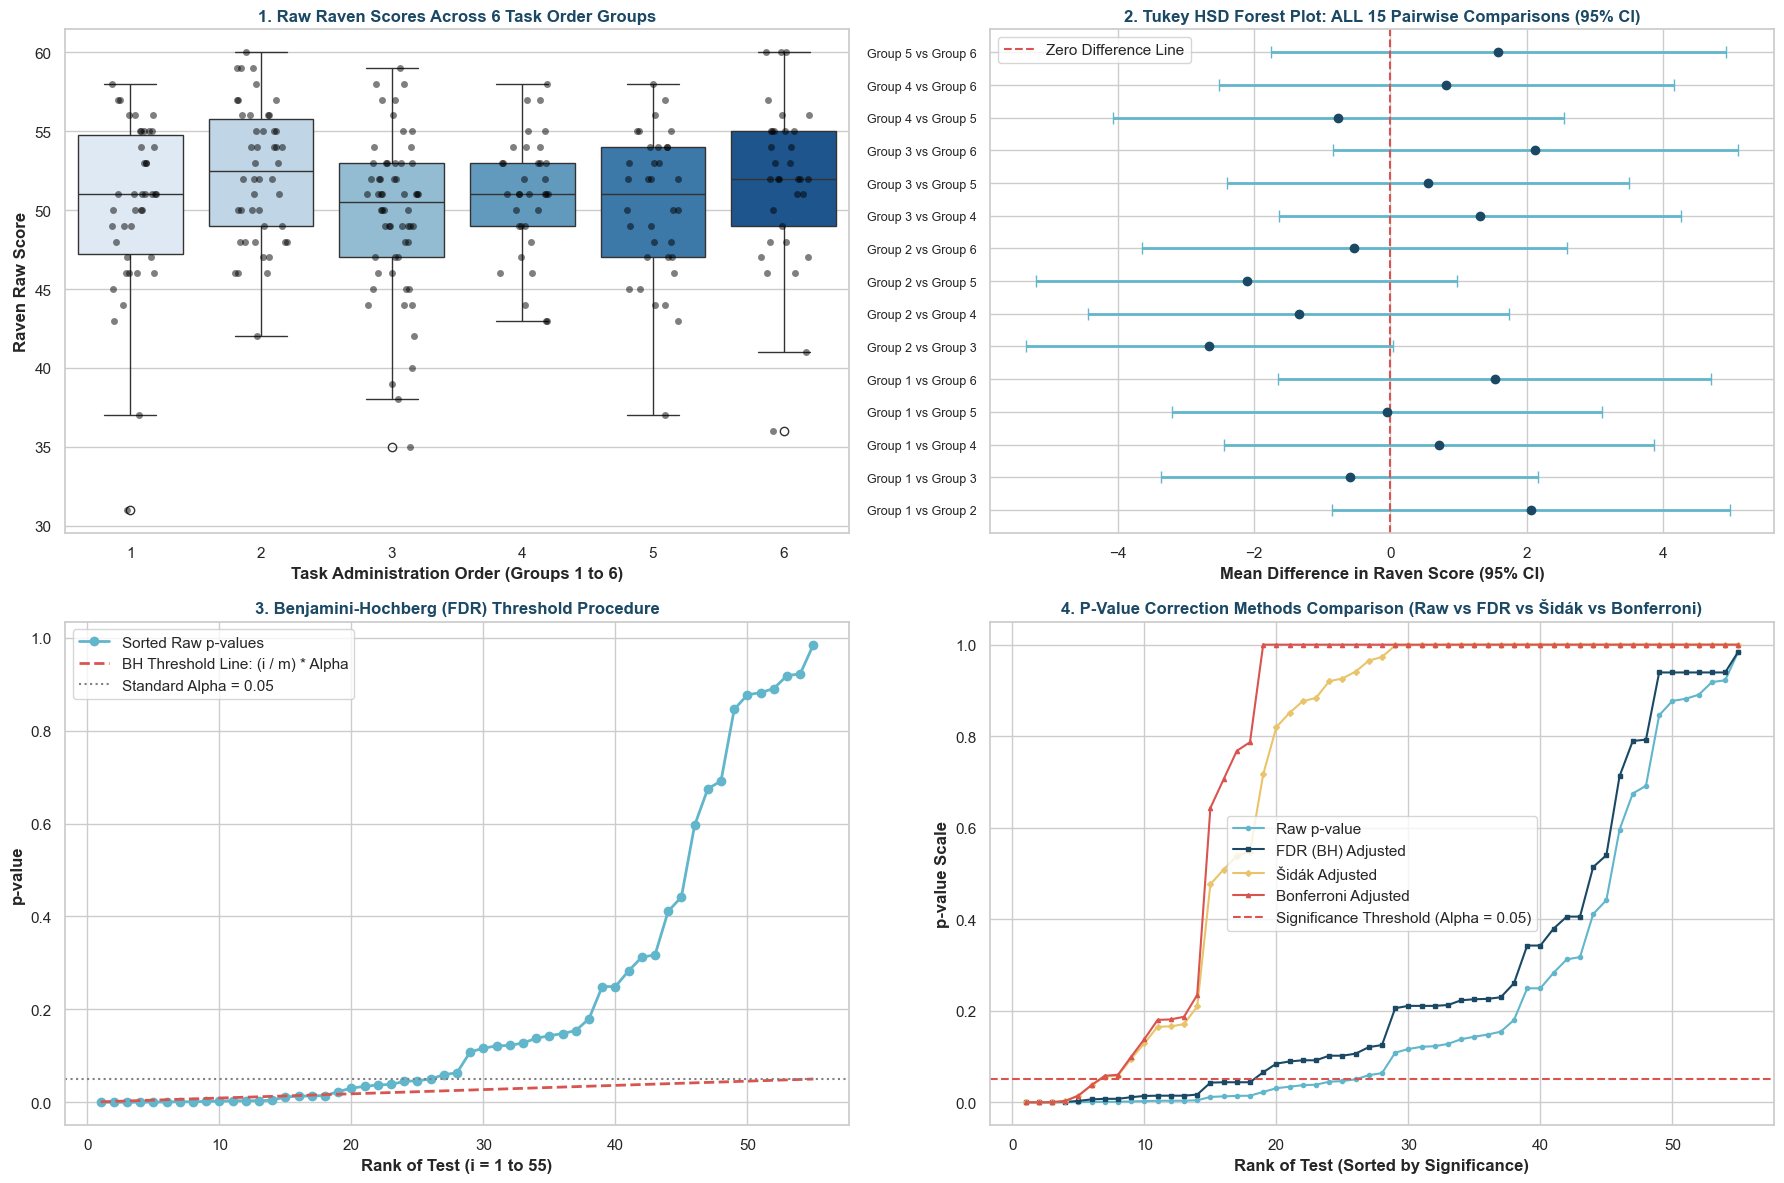

1. FULL RESULTS: TUKEY HSD POST-HOC TEST (ALL 15 PAIRWISE TASK ORDER COMPARISONS)
              Pair  meandiff  p-adj   lower  upper  reject
Group 1 vs Group 2    2.0621 0.3275 -0.8536 4.9779   False
Group 1 vs Group 3   -0.5961 0.9896 -3.3641 2.1720   False
Group 1 vs Group 4    0.7143 0.9869 -2.4375 3.8661   False
Group 1 vs Group 5   -0.0504 1.0000 -3.2022 3.1014   False
Group 1 vs Group 6    1.5325 0.7359 -1.6456 4.7105   False
Group 2 vs Group 3   -2.6582 0.0560 -5.3555 0.0392   False
Group 2 vs Group 4   -1.3478 0.8099 -4.4377 1.7420   False
Group 2 vs Group 5   -2.1125 0.3661 -5.2024 0.9773   False
Group 2 vs Group 6   -0.5296 0.9966 -3.6463 2.5870   False
Group 3 vs Group 4    1.3103 0.7981 -1.6405 4.2612   False
Group 3 vs Group 5    0.5456 0.9949 -2.4052 3.4965   False
Group 3 vs Group 6    2.1285 0.3160 -0.8504 5.1075   False
Group 4 vs Group 5   -0.7647 0.9857 -4.0782 2.5488   False
Group 4 vs Group 6    0.8182 0.9813 -2.5203 4.1567   False
Group 5 vs Group 6    1.5829 0.74

In [71]:
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)

sns.set_theme(style="whitegrid")
alpha = 0.05
primary_color = '#1b4965'
secondary_color = '#62b6cb'
accent_color = '#d9534f'
sidak_color = '#e9c46a'

valid_order_df = df[['Raven_RawScore', 'Order_ComputerTasks']].dropna()
tukey_res = pairwise_tukeyhsd(endog=valid_order_df['Raven_RawScore'],
                              groups=valid_order_df['Order_ComputerTasks'],
                              alpha=alpha)

tukey_df = pd.DataFrame(data=tukey_res._results_table.data[1:],
                        columns=tukey_res._results_table.data[0])
tukey_df['Pair'] = "Group " + tukey_df['group1'].astype(str) + " vs Group " + tukey_df['group2'].astype(str)

p_values = []
r_values = []
pairs = []

for i in range(len(primary_all_cols)):
    for j in range(i+1, len(primary_all_cols)):
        col1, col2 = primary_all_cols[i], primary_all_cols[j]
        v1, v2 = df[col1].dropna(), df[col2].dropna()
        r, p = stats.pearsonr(v1, v2)
        r_values.append(r)
        p_values.append(p)
        pairs.append(f"{col1.split('_')[0]} vs {col2.split('_')[0]}")

_, p_bonf, _, _ = multipletests(p_values, alpha=alpha, method='bonferroni')
_, p_sidak, _, _ = multipletests(p_values, alpha=alpha, method='sidak')
_, p_fdr, _, _ = multipletests(p_values, alpha=alpha, method='fdr_bh')

df_mht_all = pd.DataFrame({
    'Pair': pairs,
    'Pearson_r': r_values,
    'Raw_p': p_values,
    'FDR_p': p_fdr,
    'Sidak_p': p_sidak,
    'Bonferroni_p': p_bonf,
    'Sig_Raw': np.array(p_values) < alpha,
    'Sig_FDR': np.array(p_fdr) < alpha,
    'Sig_Sidak': np.array(p_sidak) < alpha,
    'Sig_Bonf': np.array(p_bonf) < alpha
}).sort_values(by='Raw_p').reset_index(drop=True)

m = len(df_mht_all)
df_mht_all['Rank'] = np.arange(1, m + 1)
df_mht_all['BH_Critical_Line'] = (df_mht_all['Rank'] / m) * alpha

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

sns.boxplot(x='Order_ComputerTasks', y='Raven_RawScore', data=valid_order_df, palette='Blues', ax=axes[0, 0])
sns.stripplot(x='Order_ComputerTasks', y='Raven_RawScore', data=valid_order_df, color='black', alpha=0.5, jitter=0.2, ax=axes[0, 0])
axes[0, 0].set_title('1. Raw Raven Scores Across 6 Task Order Groups', fontweight='bold', color=primary_color)
axes[0, 0].set_xlabel('Task Administration Order (Groups 1 to 6)', fontweight='bold')
axes[0, 0].set_ylabel('Raven Raw Score', fontweight='bold')

y_pos = np.arange(len(tukey_df))
axes[0, 1].errorbar(tukey_df['meandiff'], y_pos,
                     xerr=[tukey_df['meandiff'] - tukey_df['lower'], tukey_df['upper'] - tukey_df['meandiff']],
                     fmt='o', color=primary_color, ecolor=secondary_color, elinewidth=2, capsize=4)
axes[0, 1].axvline(0, color=accent_color, linestyle='--', linewidth=1.5, label='Zero Difference Line')
axes[0, 1].set_yticks(y_pos)
axes[0, 1].set_yticklabels(tukey_df['Pair'], fontsize=9)
axes[0, 1].set_title('2. Tukey HSD Forest Plot: ALL 15 Pairwise Comparisons (95% CI)', fontweight='bold', color=primary_color)
axes[0, 1].set_xlabel('Mean Difference in Raven Score (95% CI)', fontweight='bold')
axes[0, 1].legend()

axes[1, 0].plot(df_mht_all['Rank'], df_mht_all['Raw_p'], 'o-', color=secondary_color, linewidth=2, label='Sorted Raw p-values')
axes[1, 0].plot(df_mht_all['Rank'], df_mht_all['BH_Critical_Line'], '--', color=accent_color, linewidth=2, label='BH Threshold Line: (i / m) * Alpha')
axes[1, 0].axhline(alpha, color='gray', linestyle=':', label='Standard Alpha = 0.05')
axes[1, 0].set_title('3. Benjamini-Hochberg (FDR) Threshold Procedure', fontweight='bold', color=primary_color)
axes[1, 0].set_xlabel('Rank of Test (i = 1 to 55)', fontweight='bold')
axes[1, 0].set_ylabel('p-value', fontweight='bold')
axes[1, 0].legend()

axes[1, 1].plot(df_mht_all['Rank'], df_mht_all['Raw_p'], marker='o', markersize=3, label='Raw p-value', color=secondary_color)
axes[1, 1].plot(df_mht_all['Rank'], df_mht_all['FDR_p'], marker='s', markersize=3, label='FDR (BH) Adjusted', color=primary_color)
axes[1, 1].plot(df_mht_all['Rank'], df_mht_all['Sidak_p'], marker='D', markersize=3, label='Šidák Adjusted', color=sidak_color)
axes[1, 1].plot(df_mht_all['Rank'], df_mht_all['Bonferroni_p'], marker='^', markersize=3, label='Bonferroni Adjusted', color=accent_color)
axes[1, 1].axhline(alpha, color=accent_color, linestyle='--', label='Significance Threshold (Alpha = 0.05)')
axes[1, 1].set_title('4. P-Value Correction Methods Comparison (Raw vs FDR vs Šidák vs Bonferroni)', fontweight='bold', color=primary_color)
axes[1, 1].set_xlabel('Rank of Test (Sorted by Significance)', fontweight='bold')
axes[1, 1].set_ylabel('p-value Scale', fontweight='bold')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

print("="*105)
print("1. FULL RESULTS: TUKEY HSD POST-HOC TEST (ALL 15 PAIRWISE TASK ORDER COMPARISONS)")
print("="*105)
print(tukey_df[['Pair', 'meandiff', 'p-adj', 'lower', 'upper', 'reject']].to_string(index=False))

print("\n" + "="*105)
print("2. FULL RESULTS: ALL 55 PAIRWISE CORRELATIONS WITH MHT CORRECTIONS (INCLUDING ŠIDÁK)")
print("="*105)
print(df_mht_all[['Rank', 'Pair', 'Pearson_r', 'Raw_p', 'FDR_p', 'Sidak_p', 'Bonferroni_p', 'Sig_Raw', 'Sig_FDR', 'Sig_Sidak', 'Sig_Bonf']].to_string(index=False))

print("\n" + "="*105)
print("3. MHT CORRECTION SUMMARY STATISTICS")
print("="*105)
print(f"• Total Correlation Pairwise Tests: {len(df_mht_all)}")
print(f"• Significant at Raw p < 0.05: {df_mht_all['Sig_Raw'].sum()} tests")
print(f"• Significant after FDR (Benjamini-Hochberg) Correction: {df_mht_all['Sig_FDR'].sum()} tests")
print(f"• Significant after Šidák Correction: {df_mht_all['Sig_Sidak'].sum()} tests")
print(f"• Significant after Bonferroni Correction: {df_mht_all['Sig_Bonf'].sum()} tests")

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\143452773.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(task_names, rotation=45, ha='right', fontsize=8)
C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\143452773.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 2].set_xticklabels(task_names, rotation=45, ha='right', fontsize=8)


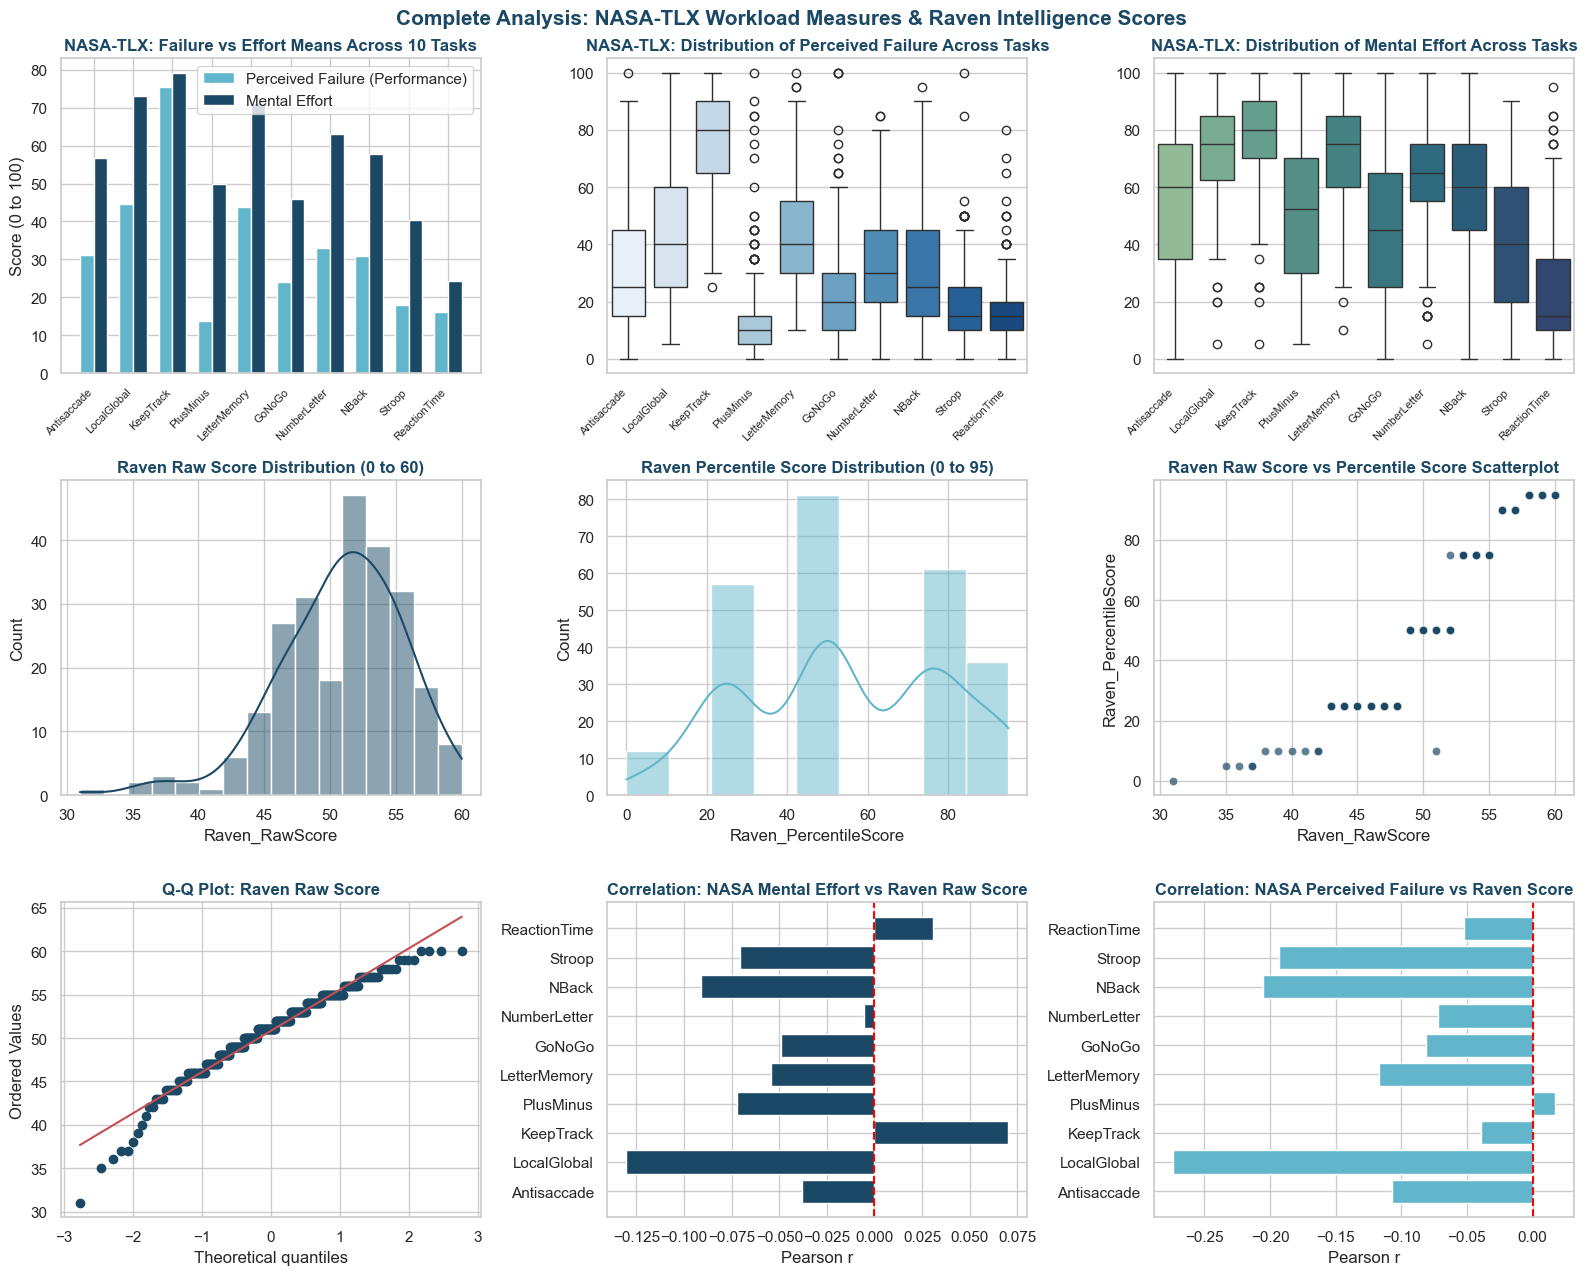

STATISTICAL ANALYSIS: RAVEN INTELLIGENCE MEASURES & NASA-TLX WORKLOAD
[Normality] Raven Raw Score Shapiro-Wilk: Stat = 0.9621, p-value = 4.1963e-06 | (< 0.05: True)
[Normality] Raven Raw Score Kolmogorov-Smirnov: Stat = 0.0934, p-value = 2.5176e-02 | (< 0.05: True)
[Normality] Raven Percentile Score Shapiro-Wilk: Stat = 0.9098, p-value = 4.7527e-11 | (< 0.05: True)

[Friedman Test] Perceived Failure Across All 10 Tasks: Q = 1189.2069, p-value = 2.5925e-250 | (< 0.05: True)
[Friedman Test] Subjective Mental Effort Across All 10 Tasks: Q = 1064.2651, p-value = 2.3771e-223 | (< 0.05: True)

--- Paired Comparisons: Subjective Mental Effort vs Perceived Failure Across Tasks ---
        Task  Mean_Effort  Mean_Failure  Mean_Diff (Eff - Fail)    t_stat          p_t  p_t_sig (<0.05)  Wilcoxon_W          p_w  Cohen_d
 Antisaccade    56.619433     31.032389               25.587045 16.694119 2.390548e-42             True      1373.0 3.859082e-32 1.062221
 LocalGlobal    73.157895     44.615385   

In [72]:

nasa_perf_cols = [
    'NASA_Antisaccade_Performance', 'NASA_LocalGlobal_Performance', 'NASA_KeepTrack_Performance',
    'NASA_PlusMinus_Performance', 'NASA_LetterMemory_Performance', 'NASA_GoNoGo_Performance',
    'NASA_NumberLetter_Performance', 'NASA_NBack_Performance', 'NASA_Stroop_Performance',
    'NASA_ReactionTime_Performance'
]

nasa_eff_cols = [
    'NASA_Antisaccade_Effort', 'NASA_LocalGlobal_Effort', 'NASA_KeepTrack_Effort',
    'NASA_PlusMinus_Effort', 'NASA_LetterMemory_Effort', 'NASA_GoNoGo_Effort',
    'NASA_NumberLetter_Effort', 'NASA_NBack_Effort', 'NASA_Stroop_Effort',
    'NASA_ReactionTime_Effort'
]

raven_cols = ['Raven_RawScore', 'Raven_PercentileScore']

task_names = [c.split('_')[1] for c in nasa_perf_cols]

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
fig.suptitle('Complete Analysis: NASA-TLX Workload Measures & Raven Intelligence Scores', fontsize=15, fontweight='bold', color=primary_color)

x_indices = np.arange(len(task_names))
width = 0.35

axes[0, 0].bar(x_indices - width/2, df[nasa_perf_cols].mean(), width, label='Perceived Failure (Performance)', color=secondary_color)
axes[0, 0].bar(x_indices + width/2, df[nasa_eff_cols].mean(), width, label='Mental Effort', color=primary_color)
axes[0, 0].set_xticks(x_indices)
axes[0, 0].set_xticklabels(task_names, rotation=45, ha='right', fontsize=8)
axes[0, 0].set_ylabel('Score (0 to 100)')
axes[0, 0].set_title('NASA-TLX: Failure vs Effort Means Across 10 Tasks', fontweight='bold', color=primary_color)
axes[0, 0].legend()

sns.boxplot(data=df[nasa_perf_cols], palette='Blues', ax=axes[0, 1])
axes[0, 1].set_xticklabels(task_names, rotation=45, ha='right', fontsize=8)
axes[0, 1].set_title('NASA-TLX: Distribution of Perceived Failure Across Tasks', fontweight='bold', color=primary_color)


sns.boxplot(data=df[nasa_eff_cols], palette='crest', ax=axes[0, 2])
axes[0, 2].set_xticklabels(task_names, rotation=45, ha='right', fontsize=8)
axes[0, 2].set_title('NASA-TLX: Distribution of Mental Effort Across Tasks', fontweight='bold', color=primary_color)

sns.histplot(df['Raven_RawScore'], kde=True, color=primary_color, ax=axes[1, 0])
axes[1, 0].set_title('Raven Raw Score Distribution (0 to 60)', fontweight='bold', color=primary_color)

sns.histplot(df['Raven_PercentileScore'], kde=True, color=secondary_color, ax=axes[1, 1])
axes[1, 1].set_title('Raven Percentile Score Distribution (0 to 95)', fontweight='bold', color=primary_color)

sns.scatterplot(x='Raven_RawScore', y='Raven_PercentileScore', data=df, color=primary_color, alpha=0.7, ax=axes[1, 2])
axes[1, 2].set_title('Raven Raw Score vs Percentile Score Scatterplot', fontweight='bold', color=primary_color)

stats.probplot(df['Raven_RawScore'].dropna(), dist="norm", plot=axes[2, 0])
axes[2, 0].get_lines()[0].set_color(primary_color)
axes[2, 0].set_title('Q-Q Plot: Raven Raw Score', fontweight='bold', color=primary_color)

effort_raven_corr = df[nasa_eff_cols + ['Raven_RawScore']].corr()['Raven_RawScore'].drop('Raven_RawScore')
axes[2, 1].barh([c.split('_')[1] for c in effort_raven_corr.index], effort_raven_corr.values, color=primary_color)
axes[2, 1].axvline(0, color='red', linestyle='--')
axes[2, 1].set_title('Correlation: NASA Mental Effort vs Raven Raw Score', fontweight='bold', color=primary_color)
axes[2, 1].set_xlabel('Pearson r')

perf_raven_corr = df[nasa_perf_cols + ['Raven_RawScore']].corr()['Raven_RawScore'].drop('Raven_RawScore')
axes[2, 2].barh([c.split('_')[1] for c in perf_raven_corr.index], perf_raven_corr.values, color=secondary_color)
axes[2, 2].axvline(0, color='red', linestyle='--')
axes[2, 2].set_title('Correlation: NASA Perceived Failure vs Raven Score', fontweight='bold', color=primary_color)
axes[2, 2].set_xlabel('Pearson r')

plt.tight_layout()
plt.show()

print("="*85)
print("STATISTICAL ANALYSIS: RAVEN INTELLIGENCE MEASURES & NASA-TLX WORKLOAD")
print("="*85)

shapiro_raven_raw = stats.shapiro(df['Raven_RawScore'].dropna())
shapiro_raven_perc = stats.shapiro(df['Raven_PercentileScore'].dropna())

std_raw = (df['Raven_RawScore'] - df['Raven_RawScore'].mean()) / df['Raven_RawScore'].std()
ks_raven_raw = stats.kstest(std_raw.dropna(), 'norm')

print(f"[Normality] Raven Raw Score Shapiro-Wilk: Stat = {shapiro_raven_raw.statistic:.4f}, p-value = {shapiro_raven_raw.pvalue:.4e} | (< 0.05: {shapiro_raven_raw.pvalue < alpha})")
print(f"[Normality] Raven Raw Score Kolmogorov-Smirnov: Stat = {ks_raven_raw.statistic:.4f}, p-value = {ks_raven_raw.pvalue:.4e} | (< 0.05: {ks_raven_raw.pvalue < alpha})")
print(f"[Normality] Raven Percentile Score Shapiro-Wilk: Stat = {shapiro_raven_perc.statistic:.4f}, p-value = {shapiro_raven_perc.pvalue:.4e} | (< 0.05: {shapiro_raven_perc.pvalue < alpha})")

f_perf, p_perf = stats.friedmanchisquare(*[df[nasa_perf_cols].dropna()[c] for c in nasa_perf_cols])
f_eff, p_eff = stats.friedmanchisquare(*[df[nasa_eff_cols].dropna()[c] for c in nasa_eff_cols])

print(f"\n[Friedman Test] Perceived Failure Across All 10 Tasks: Q = {f_perf:.4f}, p-value = {p_perf:.4e} | (< 0.05: {p_perf < alpha})")
print(f"[Friedman Test] Subjective Mental Effort Across All 10 Tasks: Q = {f_eff:.4f}, p-value = {p_eff:.4e} | (< 0.05: {p_eff < alpha})")

nasa_paired_res = []
for task in task_names:
    p_col = f'NASA_{task}_Performance'
    e_col = f'NASA_{task}_Effort'
    valid = df[[p_col, e_col]].dropna()
    t_stat, p_t = stats.ttest_rel(valid[e_col], valid[p_col])
    w_stat, p_w = stats.wilcoxon(valid[e_col], valid[p_col])
    diff_ep = valid[e_col] - valid[p_col]
    d_val = np.mean(diff_ep) / np.std(diff_ep, ddof=1)
    
    nasa_paired_res.append({
        'Task': task,
        'Mean_Effort': valid[e_col].mean(),
        'Mean_Failure': valid[p_col].mean(),
        'Mean_Diff (Eff - Fail)': valid[e_col].mean() - valid[p_col].mean(),
        't_stat': t_stat,
        'p_t': p_t,
        'p_t_sig (<0.05)': p_t < alpha,
        'Wilcoxon_W': w_stat,
        'p_w': p_w,
        'Cohen_d': d_val
    })

df_nasa_paired = pd.DataFrame(nasa_paired_res)
print("\n--- Paired Comparisons: Subjective Mental Effort vs Perceived Failure Across Tasks ---")
print(df_nasa_paired.to_string(index=False))

## <span style="color: yellow; font-size: 40px;">***Part3***</span>

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\670116461.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Group_Label', y='Pearson_r', data=df_pairs, palette='Set2', ax=axes[1])


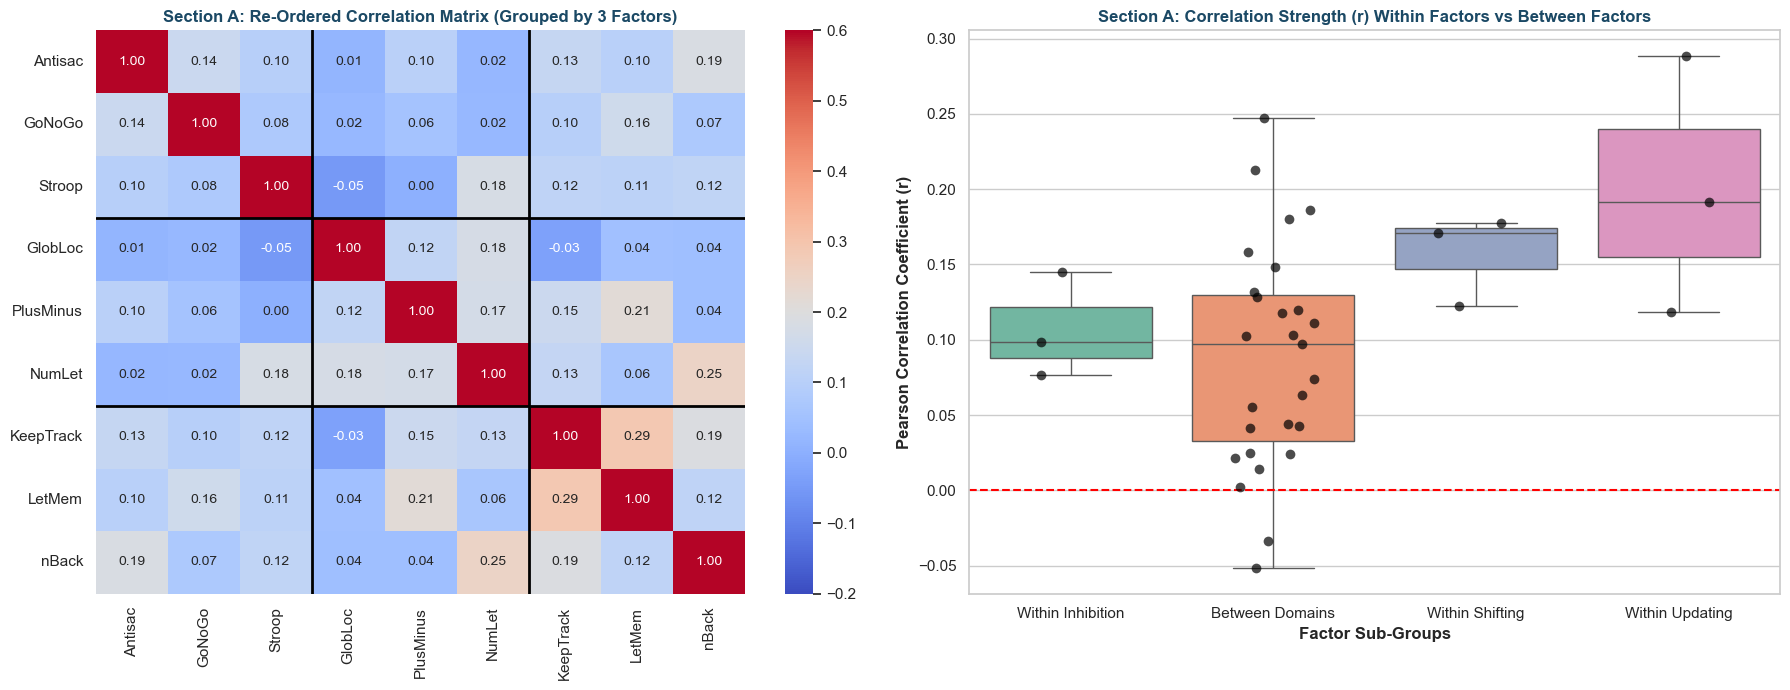

SECTION A: SUB-GROUP CORRELATION DIFFERENCES (ANOVA & KRUSKAL-WALLIS)
One-Way ANOVA Across 4 Groups: F = 2.8523, p-value = 5.2693e-02 | (< 0.05: False)
Kruskal-Wallis Across 4 Groups: H = 6.9459, p-value = 7.3641e-02 | (< 0.05: False)


In [ ]:
alpha = 0.05
primary_color = '#1b4965'
secondary_color = '#62b6cb'
accent_color = '#d9534f'


inhibition_tasks = ['Antisac_Mean_ERR', 'GoNoGo_Mean_ERR_NoGo', 'Stroop_Median_RT_StroopEffect']
shifting_tasks = ['GlobLoc_Median_RT_Switch_Cost', 'PlusMinus_Time_Switch_Cost', 'NumLet_Median_RT_SwitchCost_Local']
updating_tasks = ['KeepTrack_ERR', 'LetMem_ERR', 'nBack_Mean_ERR_Hit']

all_9_tasks = inhibition_tasks + shifting_tasks + updating_tasks
task_labels = [t.split('_')[0] for t in all_9_tasks]


corr_p = df[all_9_tasks].corr(method='pearson')


domain_map = {}
for t in inhibition_tasks: domain_map[t] = 'Inhibition'
for t in shifting_tasks: domain_map[t] = 'Shifting'
for t in updating_tasks: domain_map[t] = 'Updating'


pair_records = []
for i in range(len(all_9_tasks)):
    for j in range(i + 1, len(all_9_tasks)):
        t1, t2 = all_9_tasks[i], all_9_tasks[j]
        d1, d2 = domain_map[t1], domain_map[t2]
        r_val = corr_p.loc[t1, t2]
        
        is_intra = (d1 == d2)
        group_label = f"Within {d1}" if is_intra else "Between Domains"
        category = "Intra-Domain (Same Factor)" if is_intra else "Inter-Domain (Different Factors)"
        
        pair_records.append({
            'Task_1': t1.split('_')[0],
            'Task_2': t2.split('_')[0],
            'Pair_Name': f"{t1.split('_')[0]} - {t2.split('_')[0]}",
            'Domain_1': d1,
            'Domain_2': d2,
            'Group_Label': group_label,
            'Category': category,
            'Is_Intra': is_intra,
            'Pearson_r': r_val
        })

df_pairs = pd.DataFrame(pair_records)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))


sns.heatmap(corr_p, annot=True, cmap='coolwarm', vmin=-0.2, vmax=0.6, fmt='.2f',
            xticklabels=task_labels, yticklabels=task_labels, ax=axes[0])
axes[0].set_title('Section A: Re-Ordered Correlation Matrix (Grouped by 3 Factors)', fontweight='bold', color=primary_color)


axes[0].axhline(3, color='black', linewidth=2)
axes[0].axvline(3, color='black', linewidth=2)
axes[0].axhline(6, color='black', linewidth=2)
axes[0].axvline(6, color='black', linewidth=2)


sns.boxplot(x='Group_Label', y='Pearson_r', data=df_pairs, palette='Set2', ax=axes[1])
sns.stripplot(x='Group_Label', y='Pearson_r', data=df_pairs, color='black', size=7, alpha=0.7, jitter=0.2, ax=axes[1])
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Section A: Correlation Strength (r) Within Factors vs Between Factors', fontweight='bold', color=primary_color)
axes[1].set_xlabel('Factor Sub-Groups', fontweight='bold')
axes[1].set_ylabel('Pearson Correlation Coefficient (r)', fontweight='bold')

plt.tight_layout()
plt.show()


subgroups = [g['Pearson_r'].values for _, g in df_pairs.groupby('Group_Label')]
f_sub, p_sub = stats.f_oneway(*subgroups)
kw_sub, p_kw_sub = stats.kruskal(*subgroups)

print("="*85)
print("SECTION A: SUB-GROUP CORRELATION DIFFERENCES (ANOVA & KRUSKAL-WALLIS)")
print("="*85)
print(f"One-Way ANOVA Across 4 Groups: F = {f_sub:.4f}, p-value = {p_sub:.4e} | (< 0.05: {p_sub < alpha})")
print(f"Kruskal-Wallis Across 4 Groups: H = {kw_sub:.4f}, p-value = {p_kw_sub:.4e} | (< 0.05: {p_kw_sub < alpha})")

C:\Users\Asus\AppData\Local\Temp\ipykernel_6608\811388829.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Category', y='Pearson_r', data=df_pairs, palette=[primary_color, secondary_color], ax=axes[0], inner=None)


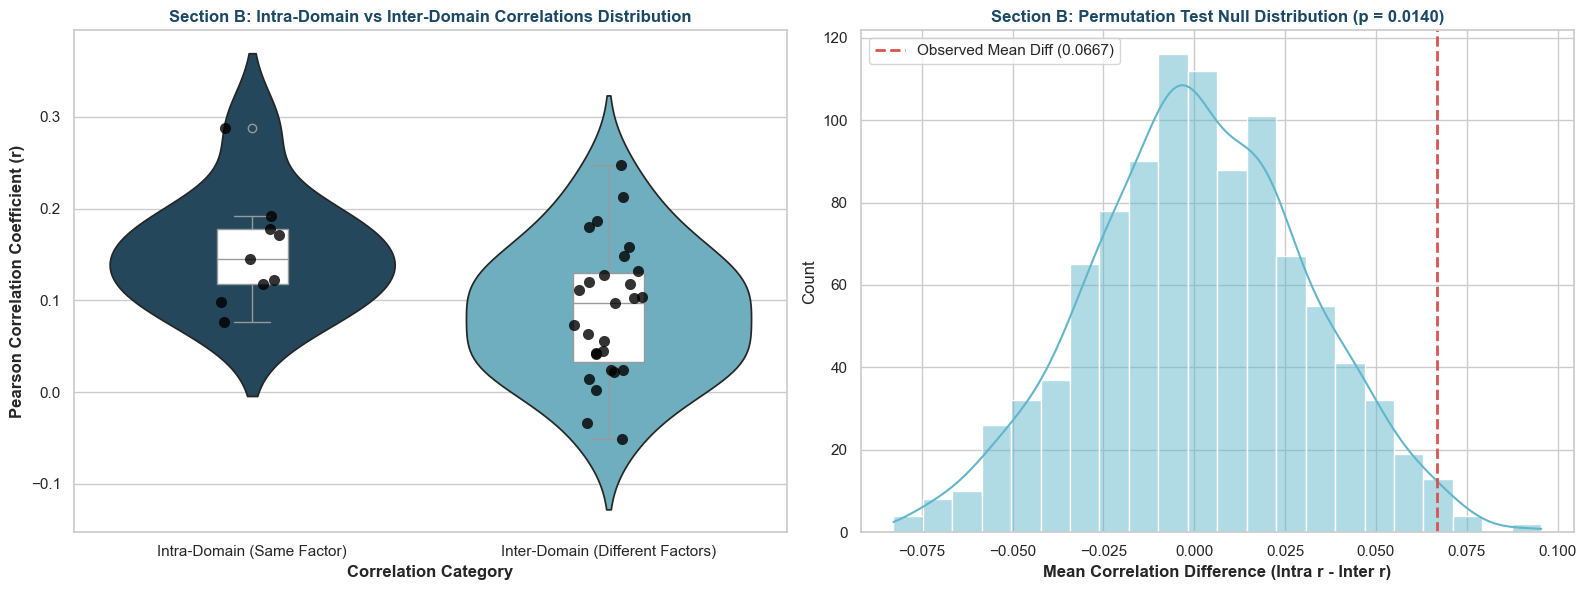

SECTION B: STATISTICAL HYPOTHESIS TESTING (3-FACTOR MODEL VALIDATION)
Intra-Domain Pairs (n = 9): Mean r = 0.1544, SD = 0.0630
Inter-Domain Pairs (n = 27): Mean r = 0.0877, SD = 0.0738
Observed Mean Difference (Intra - Inter): 0.0667 | 95% CI = [0.0170, 0.1164]

[Normality] Shapiro-Wilk Intra-Domain r: Stat = 0.9234, p-value = 0.4210
[Normality] Shapiro-Wilk Inter-Domain r: Stat = 0.9856, p-value = 0.9616

[Parametric] Independent t-test: t = 2.4259, p-value = 2.0727e-02 | (< 0.05: True)
[Non-Parametric] Mann-Whitney U Test: U = 183.0, p-value = 2.5846e-02 | (< 0.05: True)
[Resampling] Permutation Test (1000 Iterations): p-value = 1.4000e-02 | (< 0.05: True)
[Effect Size] Cohen's d = 0.9337


In [ ]:
intra_r = df_pairs[df_pairs['Is_Intra']]['Pearson_r'].values
inter_r = df_pairs[~df_pairs['Is_Intra']]['Pearson_r'].values


shapiro_intra = stats.shapiro(intra_r)
shapiro_inter = stats.shapiro(inter_r)


t_stat, p_t = stats.ttest_ind(intra_r, inter_r)
u_stat, p_u = stats.mannwhitneyu(intra_r, inter_r)


pooled_std = np.sqrt(((len(intra_r)-1)*np.std(intra_r, ddof=1)**2 + (len(inter_r)-1)*np.std(inter_r, ddof=1)**2) / (len(intra_r)+len(inter_r)-2))
mean_diff = np.mean(intra_r) - np.mean(inter_r)
d_val = mean_diff / pooled_std


se_diff = np.sqrt(np.std(intra_r, ddof=1)**2/len(intra_r) + np.std(inter_r, ddof=1)**2/len(inter_r))
ci_low = mean_diff - 1.96 * se_diff
ci_upp = mean_diff + 1.96 * se_diff


np.random.seed(42)
n_permutations = 1000
combined_r = np.concatenate([intra_r, inter_r])
n_intra = len(intra_r)

perm_diffs = []
for _ in range(n_permutations):
    shuffled = np.random.permutation(combined_r)
    perm_intra = shuffled[:n_intra]
    perm_inter = shuffled[n_intra:]
    perm_diffs.append(np.mean(perm_intra) - np.mean(perm_inter))

perm_diffs = np.array(perm_diffs)
p_perm = np.mean(perm_diffs >= mean_diff)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))


sns.violinplot(x='Category', y='Pearson_r', data=df_pairs, palette=[primary_color, secondary_color], ax=axes[0], inner=None)
sns.boxplot(x='Category', y='Pearson_r', data=df_pairs, width=0.2, color='white', ax=axes[0])
sns.stripplot(x='Category', y='Pearson_r', data=df_pairs, color='black', size=8, alpha=0.8, jitter=0.1, ax=axes[0])
axes[0].set_title('Section B: Intra-Domain vs Inter-Domain Correlations Distribution', fontweight='bold', color=primary_color)
axes[0].set_xlabel('Correlation Category', fontweight='bold')
axes[0].set_ylabel('Pearson Correlation Coefficient (r)', fontweight='bold')


sns.histplot(perm_diffs, kde=True, color=secondary_color, ax=axes[1])
axes[1].axvline(mean_diff, color=accent_color, linestyle='--', linewidth=2, label=f'Observed Mean Diff ({mean_diff:.4f})')
axes[1].set_title(f'Section B: Permutation Test Null Distribution (p = {p_perm:.4f})', fontweight='bold', color=primary_color)
axes[1].set_xlabel('Mean Correlation Difference (Intra r - Inter r)', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

print("="*85)
print("SECTION B: STATISTICAL HYPOTHESIS TESTING (3-FACTOR MODEL VALIDATION)")
print("="*85)
print(f"Intra-Domain Pairs (n = {len(intra_r)}): Mean r = {np.mean(intra_r):.4f}, SD = {np.std(intra_r, ddof=1):.4f}")
print(f"Inter-Domain Pairs (n = {len(inter_r)}): Mean r = {np.mean(inter_r):.4f}, SD = {np.std(inter_r, ddof=1):.4f}")
print(f"Observed Mean Difference (Intra - Inter): {mean_diff:.4f} | 95% CI = [{ci_low:.4f}, {ci_upp:.4f}]")
print(f"\n[Normality] Shapiro-Wilk Intra-Domain r: Stat = {shapiro_intra.statistic:.4f}, p-value = {shapiro_intra.pvalue:.4f}")
print(f"[Normality] Shapiro-Wilk Inter-Domain r: Stat = {shapiro_inter.statistic:.4f}, p-value = {shapiro_inter.pvalue:.4f}")
print(f"\n[Parametric] Independent t-test: t = {t_stat:.4f}, p-value = {p_t:.4e} | (< 0.05: {p_t < alpha})")
print(f"[Non-Parametric] Mann-Whitney U Test: U = {u_stat:.1f}, p-value = {p_u:.4e} | (< 0.05: {p_u < alpha})")
print(f"[Resampling] Permutation Test (1000 Iterations): p-value = {p_perm:.4e} | (< 0.05: {p_perm < alpha})")
print(f"[Effect Size] Cohen's d = {d_val:.4f}")